# Bengaluru House Price Prediction
## Session 1: setup, load and first-pass cleaning

**Objective.** Load the raw Bengaluru house-price data, understand it, and reduce it to a clean frame that holds only the columns that can feed the model (`location`, `size`, `total_sqft`, `bath`, `price`) with no missing values.

**Target.** `price`, in **lakhs of INR** (1 lakh = 100,000 INR). The `price` column stays in lakhs throughout the project; nothing is converted in this session.

**Out of scope for this session.** Cleaning `total_sqft` (ranges and unit strings, Session 2), encoding, scaling and the train/test split.

## 1. Setup and load

`df_raw` holds the data exactly as loaded and is never modified; every cleaning step works on a new frame.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__}")

Python 3.13.18 | pandas 3.1.0


In [2]:
# Where the CSV can be: the notebook sits in model/, so the data folder is one level up
# (or just data/ if Jupyter was started from the repository root). Kaggle's own file name is
# Bengaluru_House_Data.csv; the same data also circulates as bengaluru_house_prices.csv.
locations = [
    Path("../data/bengaluru_house_prices.csv"),
    Path("../data/Bengaluru_House_Data.csv"),
    Path("data/bengaluru_house_prices.csv"),
    Path("data/Bengaluru_House_Data.csv"),
]

csv_path = None
for path in locations:
    if path.exists():
        csv_path = path
        break

if csv_path is None:
    raise FileNotFoundError("No CSV found. Save the Kaggle file in the repository's data/ folder (see the README).")

df_raw = pd.read_csv(csv_path)
print(f"Loaded {csv_path}")

Loaded ../data/bengaluru_house_prices.csv


## 2. Inspect the raw data

In [3]:
print(df_raw.shape)
display(df_raw.head())
df_raw.dtypes

(13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


area_type           str
availability        str
location            str
size                str
society             str
total_sqft          str
bath            float64
balcony         float64
price           float64
dtype: object

Text columns appear as `object` in pandas below 3 and as `str` from pandas 3 on; either way they are non-numeric. `total_sqft` is one of them: it holds ranges and unit strings, so it stays untouched until Session 2.

In [4]:
null_counts = df_raw.isnull().sum()
pd.DataFrame({"nulls": null_counts, "pct_missing": (null_counts / len(df_raw) * 100).round(2)})

,nulls,pct_missing
area_type,0,0.00
availability,0,0.00
location,1,0.01
size,16,0.12
society,5502,41.31
total_sqft,0,0.00
bath,73,0.55
balcony,609,4.57
price,0,0.00


In [5]:
df_raw["area_type"].value_counts()

area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64

In [6]:
# Observation only: nothing is removed in this session.
n_repeats = int(df_raw.duplicated().sum())
print(f"Rows that exactly repeat an earlier row: {n_repeats:,} ({n_repeats / len(df_raw):.2%})")

Rows that exactly repeat an earlier row: 529 (3.97%)


### Findings

Every figure the brief expected holds: 13,320 rows and 9 columns; `society` is missing for 41.3% of the rows (5,502), `balcony` for 609, `bath` for 73, `size` for 16 and `location` for 1. `area_type`, `availability`, `total_sqft` and `price` have no nulls. `price` is numeric; `total_sqft` is text.

529 rows exactly repeat an earlier row (all nine raw columns). They are left in place; whether to remove them is decided in Session 4, before the train/test split (see the open items at the end).

## 3. Drop columns that cannot feed the model

Evidence for each decision, computed from the raw data:

In [7]:
DROP_COLS = ["area_type", "availability", "society", "balcony"]

evidence = pd.DataFrame({
    "dtype": df_raw[DROP_COLS].dtypes.astype(str),
    "pct_missing": (df_raw[DROP_COLS].isnull().mean() * 100).round(1),
    "n_unique": df_raw[DROP_COLS].nunique(),
    "top_values": pd.Series({c: df_raw[c].value_counts().head(3).to_dict() for c in DROP_COLS}),
})
with pd.option_context("display.max_colwidth", None):
    display(evidence)

,dtype,pct_missing,n_unique,top_values
area_type,str,0.0,4,"{'Super built-up Area': 8790, 'Built-up Area': 2418, 'Plot Area': 2025}"
availability,str,0.0,81,"{'Ready To Move': 10581, '18-Dec': 307, '18-May': 295}"
society,str,41.3,2688,"{'GrrvaGr': 80, 'PrarePa': 76, 'Sryalan': 59}"
balcony,float64,4.6,4,"{2.0: 5113, 1.0: 4897, 3.0: 1672}"


**Justification for each drop**

- **`area_type`**: it changes what `total_sqft` measures (super built-up, built-up, carpet or plot area), so it may well carry signal; it is left out of this first baseline as a judgment call, not because it is unusable, and it is logged in the README as a known limitation to test in Session 5.
- **`availability`**: it mixes the labels "Ready To Move" and "Immediate Possession" with possession-month strings such as "18-Dec" (81 distinct values in all), so it describes when a unit can be occupied rather than what the property is, and it cannot be used without parsing dates.
- **`society`**: 41.3% of its values are missing and the rest hold 2,688 distinct names, so it would be a sparse, high-cardinality categorical that cannot be encoded reliably.
- **`balcony`**: it is a minor amenity count with only four distinct values (0 to 3) and 609 missing entries, so dropping it avoids imputing values for otherwise complete rows and keeps the baseline on the core features.

In [8]:
df = df_raw.drop(columns=DROP_COLS)
assert len(df) == len(df_raw)  # dropping columns never removes rows
df.shape

(13320, 5)

## 4. Remaining nulls in `location`, `size` and `bath`

Count them, look at where they sit, and check that they do not cluster before dropping them.

In [9]:
CORE_NULL_COLS = ["location", "size", "bath"]

nulls_now = df.isnull().sum()
display(nulls_now.to_frame("nulls"))
assert set(nulls_now[nulls_now > 0].index) <= set(CORE_NULL_COLS), "unexpected nulls outside location/size/bath"

,nulls
location,1
size,16
total_sqft,0
bath,73
price,0


In [10]:
null_flags = df[CORE_NULL_COLS].isnull()
null_mask = null_flags.any(axis=1)
n_null_rows = int(null_mask.sum())

print(f"Rows with at least one null in {CORE_NULL_COLS}: {n_null_rows} "
      f"({n_null_rows / len(df):.2%} of {len(df):,})")

# Which of the three columns are null together? (True = null)
null_flags[null_mask].value_counts().rename("rows").reset_index()

Rows with at least one null in ['location', 'size', 'bath']: 74 (0.56% of 13,320)


,location,size,bath,rows
0,False,False,True,57
1,False,True,True,16
2,True,False,False,1


In [11]:
# Raw rows (dropped columns still visible) for the null `location` and `size` cases.
df_raw[df["location"].isnull() | df["size"].isnull()]

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
568,Super built-up Area,Ready To Move,NaN,3 BHK,Grare S,1600,3.0,2.0,86.000
579,Plot Area,Immediate Possession,Sarjapur Road,NaN,Asiss B,1200 - 2400,NaN,NaN,34.185
1775,Plot Area,Immediate Possession,IVC Road,NaN,Orana N,2000 - 5634,NaN,NaN,124.000
2264,Plot Area,Immediate Possession,Banashankari,NaN,NaN,2400,NaN,NaN,460.000
2809,Plot Area,Immediate Possession,Sarjapur Road,NaN,AsdiaAr,1200 - 2400,NaN,NaN,28.785
2862,Plot Area,Immediate Possession,Devanahalli,NaN,Ajleyor,1500 - 2400,NaN,NaN,46.800
5333,Plot Area,Immediate Possession,Devanahalli,NaN,Emngs S,2100 - 5405,NaN,NaN,177.115
6423,Plot Area,Immediate Possession,Whitefield,NaN,SRniaGa,2324,NaN,NaN,26.730
6636,Plot Area,Immediate Possession,Jigani,NaN,S2enste,1500,NaN,NaN,25.490
6719,Plot Area,Immediate Possession,Hoskote,NaN,SJowsn,800 - 2660,NaN,NaN,28.545


### What the null rows have in common

A read-only look: `total_sqft` is not modified here (cleaning it is Session 2); the cell only tests whether each value is written as a range such as "2100 - 2850".

In [12]:
is_range = df["total_sqft"].str.contains(r"\d\s*-\s*\d")

groups = {
    "all rows": pd.Series(True, index=df.index),
    "any null row": null_mask,
    "bath only": null_flags["bath"] & ~null_flags["size"] & ~null_flags["location"],
    "size and bath": null_flags["size"],
    "location only": null_flags["location"],
}
rows = []
for name, m in groups.items():
    rows.append({
        "group": name,
        "rows": int(m.sum()),
        "total_sqft is a range": int(is_range[m].sum()),
        "% range": round(is_range[m].mean() * 100, 1),
        "% balcony also missing": round(df_raw.loc[m, "balcony"].isnull().mean() * 100, 1),
        "% Plot Area": round(df_raw.loc[m, "area_type"].str.contains("Plot").mean() * 100, 1),
    })
pd.DataFrame(rows).set_index("group")

,rows,total_sqft is a range,% range,% balcony also missing,% Plot Area
group,,,,,
all rows,13320,201,1.5,4.6,15.2
any null row,74,57,77.0,98.6,21.6
bath only,57,49,86.0,100.0,0.0
size and bath,16,8,50.0,100.0,100.0
location only,1,0,0.0,0.0,0.0


### Do the null rows cluster?

The brief asks for a check by `location`: the table below lists the locations that hold the most null rows, with each location's null rate. The second table does the same by `area_type`, read from the raw frame because the column is already gone from `df`. Location names are not cleaned yet (that is the first job of Session 3), so spelling variants of one place count as separate locations here.

In [13]:
# Null rows per location, next to the number of listings the location has in total.
loc_null = df.loc[null_mask, "location"].value_counts()   # the one null location is skipped
by_location = pd.DataFrame({
    "null_rows": loc_null,
    "all_rows": df["location"].value_counts().loc[loc_null.index],
})
by_location["null_rate_%"] = (by_location["null_rows"] / by_location["all_rows"] * 100).round(1)

print(f"{loc_null.sum()} null rows have a known location, spread over {len(loc_null)} of the "
      f"{df['location'].nunique():,} locations in the data.")
by_location.head(10)

73 null rows have a known location, spread over 36 of the 1,305 locations in the data.


,null_rows,all_rows,null_rate_%
location,,,
Kanakpura Road,7,273,2.6
Sarjapur Road,7,399,1.8
Whitefield,6,540,1.1
Devanahalli,5,45,11.1
JP Nagar,5,72,6.9
Hennur,3,55,5.5
Yelahanka,3,213,1.4
Jakkur,3,71,4.2
KR Puram,3,91,3.3


In [14]:
# area_type is already dropped from df, but the raw frame still has it: diagnostic use only.
area_check = pd.DataFrame({
    "null_rows": df_raw.loc[null_mask, "area_type"].value_counts(),
    "all_rows": df_raw["area_type"].value_counts(),
}).fillna(0).astype(int)
area_check["null_rate_%"] = (area_check["null_rows"] / area_check["all_rows"] * 100).round(2)
exp_area = n_null_rows * area_check["all_rows"] / area_check["all_rows"].sum()  # expected if scattered at random
area_check["expected_if_random"] = exp_area.round(1)
area_check["lift"] = (area_check["null_rows"] / exp_area).round(2)
area_check.sort_values("null_rows", ascending=False)

,null_rows,all_rows,null_rate_%,expected_if_random,lift
area_type,,,,,
Super built-up Area,50,8790,0.57,48.8,1.02
Plot Area,16,2025,0.79,11.2,1.42
Built-up Area,8,2418,0.33,13.4,0.60
Carpet Area,0,87,0.00,0.5,0.00


### Findings: where the null rows sit

- **74 distinct rows are affected, not the 90 you get by adding the three column counts.** The nulls overlap: the 16 `size` nulls are all also `bath` nulls, 57 rows are null in `bath` only, and 1 row is null in `location` only.
- **Not one location.** 73 of the rows have a known location, spread over 36 of the 1,305 locations; the busiest two hold 7 each (9.6%). A few small locations have high null rates (Devanahalli 5 of 45 listings, JP Nagar 5 of 72, Hennur 3 of 55), but each rests on 3 to 5 rows, too few to say more.
- **The clearest pattern is listing type, not place.** The 16 `size` nulls are all Plot Area listings with availability "Immediate Possession". Of the 57 `bath`-only nulls, 49 (86%) have `total_sqft` written as a range, against 1.5% of all rows, and every `bath` null also lacks `balcony`.
- **By `area_type`** the null rate is 0.3% to 0.8% in each of the three large types (0 of 87 in Carpet Area). Plot Area is the only type clearly above its random share (16 null rows against about 11 expected): those are the 16 `size` nulls.

**Decision: drop these rows rather than impute them.** `location` has no sensible fill value, and `bath` is structurally tied to the bedroom count in `size`, so a median fill would invent data. The affected share is 0.56% of the rows. The drop also removes 57 of the 201 raw rows with a ranged `total_sqft`, so 144 remain for Session 2.

In [15]:
rows_before = len(df)
df = df.dropna()  # the index is deliberately not reset: it keeps each row traceable to its line in the raw CSV
rows_after = len(df)
assert rows_before - rows_after == n_null_rows  # exactly the rows flagged above

print(f"Rows before: {rows_before:,} | after: {rows_after:,} | removed: {rows_before - rows_after:,} "
      f"({(rows_before - rows_after) / rows_before:.2%})")

Rows before: 13,320 | after: 13,246 | removed: 74 (0.56%)


## 5. Final check of the Session 1 frame

In [16]:
assert list(df.columns) == ["location", "size", "total_sqft", "bath", "price"]
assert df.isnull().sum().sum() == 0

print(f"Final shape: {df.shape}")

null_summary = pd.DataFrame({"nulls_before": df_raw.isnull().sum()})
null_summary["nulls_after"] = df.isnull().sum()  # aligns on column name; a dropped column shows as <NA>
display(null_summary.astype("Int64"))
df.head()

Final shape: (13246, 5)


,nulls_before,nulls_after
area_type,0,<NA>
availability,0,<NA>
location,1,0
size,16,0
society,5502,<NA>
total_sqft,0,0
bath,73,0
balcony,609,<NA>
price,0,0


,location,size,total_sqft,bath,price
0,Electronic City Phase II,2 BHK,1056,2.0,39.07
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00
2,Uttarahalli,3 BHK,1440,2.0,62.00
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00
4,Kothanur,2 BHK,1200,2.0,51.00


## Session 2: feature engineering

**Objective.** Turn `size` and `total_sqft` into clean numeric features (`bhk`, and `total_sqft` as a float) and add `price_per_sqft`, so that Session 3 can start on `location`.

Each choice that changes which listings the model can see (the "RK" rows, the `total_sqft` ranges and unit strings) is argued from counts below and logged in the decision log at the end.

**Cautions for the whole session**

- `price_per_sqft` is built from the target (`price`). It must **never be a model input**; it exists only to spot outliers in Session 4.
- Nothing is removed because of an extreme value (`bhk`, `price_per_sqft` or anything else): extremes are reported and left in. The 529 repeated rows are left in too.

In [17]:
# Work on a copy: df (the Session 1 result) stays untouched, and df2 is its own frame.
df2 = df.copy()
df2.shape

(13246, 5)

### Step 1. `bhk` from `size`

`size` is text such as "2 BHK", "4 Bedroom" or "1 RK". The number in front is the bedroom count, so `str.extract` with the regular expression `^(\d+)` (digits at the start of the string) pulls it out. `extract` gives NaN for every row where the pattern does not match, so asserting that nothing is NaN proves that every row matched.

In [18]:
# What follows the number? (the brief says BHK, Bedroom and RK)
print(df2["size"].str.extract(r"^\d+\s*(\w+)", expand=False).value_counts().to_dict())

bhk_text = df2["size"].str.extract(r"^(\d+)", expand=False)
assert bhk_text.notna().all(), "some `size` values have no leading integer"
df2["bhk"] = bhk_text.astype(int)

print(f"bhk runs from {df2['bhk'].min()} to {df2['bhk'].max()}; "
      f"{(df2['bhk'] >= 10).sum()} rows have 10 or more; "
      f"2 and 3 BHK make up {df2['bhk'].isin([2, 3]).mean():.1%} of rows")
df2["bhk"].value_counts().sort_index().to_frame("rows").T

{'BHK': 10718, 'Bedroom': 2515, 'RK': 13}


bhk runs from 1 to 43; 26 rows have 10 or more; 2 and 3 BHK make up 78.2% of rows


bhk,1,2,3,4,5,6,7,8,9,10,11,12,13,14,16,18,19,27,43
rows,649,5527,4832,1395,353,221,100,89,54,14,4,1,1,1,1,1,1,1,1


**The 13 "RK" rows.** "1 RK" means one room plus a kitchen: there is no separate bedroom, so `bhk` has no obvious value for them. The evidence is the rows themselves and how they compare with 1 BHK flats.

In [19]:
is_rk = df2["size"].str.contains("RK")
is_1bhk = df2["size"].str.match(r"1\s*BHK")

for name, mask in [("1 RK", is_rk), ("1 BHK", is_1bhk)]:
    print(f"{name:<6}{mask.sum():>4} rows | median price {df2.loc[mask, 'price'].median():5.2f} lakh | "
          f"median bath {df2.loc[mask, 'bath'].median()}")

df2.loc[is_rk, ["location", "size", "total_sqft", "bath", "price"]]

1 RK    13 rows | median price 25.25 lakh | median bath 1.0
1 BHK  531 rows | median price 32.00 lakh | median bath 1.0


,location,size,total_sqft,bath,price
24,Thanisandra,1 RK,510,1.0,25.25
782,Thanisandra,1 RK,445,1.0,28.00
1363,Thanisandra,1 RK,510,1.0,25.25
2486,Bhoganhalli,1 RK,296,1.0,22.89
2557,Anekal,1 RK,351,1.0,16.00
2788,Rachenahalli,1 RK,440,1.0,28.00
4876,Electronic City,1 RK,435,1.0,19.50
5079,Whitefield,1 RK,905,1.0,52.00
5285,Rachenahalli,1 RK,385 - 440,1.0,19.80
6586,Electronics City Phase 1,1 RK,360,1.0,16.90


**Decision: keep the 13 "RK" rows and give them `bhk = 1`.** All 13 are "1 RK" with one bathroom and a small area (the largest is 905 sqft), and their median price (25.25 lakh) is below that of 1 BHK flats (32.00 lakh), so they belong at the bottom of the bedroom scale, next to 1 BHK. Dropping them would remove a whole listing type for 13 rows (0.10% of the data), and `bhk = 0` would create a value that occurs only 13 times. The cost is that the model cannot tell a 1 RK from a 1 BHK. Logged as decision 7.

### Step 2. `total_sqft` as a number

`total_sqft` is text. `pd.to_numeric(..., errors="coerce")` converts what is a plain number and turns everything else into NaN instead of raising an error. That sorts the column into three groups: plain numbers, ranges ("2100 - 2850") and unit strings ("34.46Sq. Meter"). Each group gets its own rule, and the rules for the ranges and the unit strings change which listings the model sees, so each is argued below.

In [20]:
as_number = pd.to_numeric(df2["total_sqft"], errors="coerce")   # plain numbers -> float; everything else -> NaN
is_plain = as_number.notna()
is_range = df2["total_sqft"].str.contains(r"\d\s*-\s*\d")
is_unit = ~is_plain & ~is_range
assert not (is_plain & is_range).any()                           # no row is counted twice

print(f"plain numbers {is_plain.sum():,} | ranges {is_range.sum()} | unit strings {is_unit.sum()} "
      f"| total {is_plain.sum() + is_range.sum() + is_unit.sum():,} of {len(df2):,} rows")

plain numbers 13,056 | ranges 144 | unit strings 46 | total 13,246 of 13,246 rows


**Ranges become their midpoint.** Split each range at the dash into a lower and an upper end, check that both ends are numbers, and average them. The midpoint is the usual convention, but it hides how wide a range is, so the widest ones are shown.

In [21]:
ends = df2.loc[is_range, "total_sqft"].str.split("-", expand=True)   # one column per end
assert ends.shape[1] == 2, "a range has more than one dash"
low = pd.to_numeric(ends[0], errors="coerce")
high = pd.to_numeric(ends[1], errors="coerce")
assert low.notna().all() and high.notna().all(), "a range end is not a number"
assert (high >= low).all(), "a range runs downwards"

midpoint = (low + high) / 2
spread = high - low
print(f"Median spread of the {len(spread)} ranges: {spread.median():.0f} sqft")

widest = pd.DataFrame({
    "total_sqft": df2.loc[is_range, "total_sqft"],
    "spread": spread,
    "upper / lower": (high / low).round(2),
})
widest.nlargest(5, "spread")

Median spread of the 144 ranges: 160 sqft


,total_sqft,spread,upper / lower
122,3067 - 8156,5089.00,2.66
5940,1349 - 3324,1975.00,2.46
672,3090 - 5002,1912.00,1.62
3174,2249.81 - 4112.19,1862.38,1.83
1694,4000 - 5249,1249.00,1.31


**Unit strings.** 46 rows give a number followed by a unit. The regular expression `^([\d.]+)\s*(.+)$` splits each of them into the number and the unit text, and the per-unit counts decide what to do with them.

In [22]:
units = df2.loc[is_unit, "total_sqft"].str.extract(r"^([\d.]+)\s*(.+)$")   # column 0: the number, column 1: the unit text
units.columns = ["value", "unit"]
assert units.notna().all().all(), "a unit string did not match number + unit"
units["value"] = pd.to_numeric(units["value"])

units.groupby("unit")["value"].agg(["count", "min", "max"]).sort_values("count", ascending=False)

,count,min,max
unit,,,
Sq. Meter,17,24.00,3040.0
Sq. Yards,15,45.00,2940.0
Acres,8,1.25,30.0
Guntha,2,24.00,38.0
Cents,2,3.00,1500.0
Grounds,1,1.00,1.0
Perch,1,4125.00,4125.0


In [23]:
CONVERT = {"Sq. Meter": 10.7639, "Sq. Yards": 9}    # square feet in one of each unit
converted = units[units["unit"].isin(CONVERT)]
left_out = units[~units["unit"].isin(CONVERT)]
print(f"convert {len(converted)} rows, leave out {len(left_out)} rows")

# The rows that would be left out:
df2.loc[left_out.sort_values("unit").index, ["location", "total_sqft", "bath", "price"]]

convert 32 rows, leave out 14 rows


,location,total_sqft,bath,price
1019,Marathi Layout,5.31Acres,1.0,110.0
1086,Narasapura,30Acres,2.0,29.5
6333,Harohalli,2.09Acres,2.0,200.0
7334,Kanakpura Road,2Acres,1.0,125.0
7607,Bommenahalli,15Acres,3.0,217.0
7726,Kanakpura Road,1.26Acres,1.0,125.0
10488,2 Bedroom Furnished Farm House in Kolar Road,1.25Acres,2.0,200.0
11615,arudi,6Acres,2.0,80.0
5453,Kannur,3Cents,6.0,75.0
7001,Thyagaraja Nagar,1500Cents,6.0,290.0


**Decision: convert Sq. Meter (× 10.7639) and Sq. Yards (× 9), and drop the other 14 rows.**

- Square metres and square yards have exact, universal conversion factors (1 m² = 10.7639 sq ft, 1 yd² = 9 sq ft), so these 32 rows (17 + 15) become square feet without guessing.
- The other 14 rows (8 Acres, 2 Cents, 2 Guntha, 1 Perch, 1 Grounds) are land-parcel units. Acres are farmland scale: the smallest listing here, 1.25 acres, is already 54,450 sq ft. Cents, guntha, perch and ground are defined differently from region to region. The rows also look like plots rather than flats ("4125Perch" with 9 bathrooms, "30Acres" for 29.5 lakh).
- The cost: 14 rows (0.11% of 13,246) go, so the model never sees listings quoted in those units.
- Alternatives not taken: dropping all 46 (0.35% of the rows) would also discard 32 ordinary listings; converting every unit needs regional definitions that are hard to defend.

In [24]:
# Fill each group of rows. .loc[row labels] = values lines the values up by row label.
sqft = as_number.copy()                                                           # plain numbers; the rest are NaN so far
sqft.loc[midpoint.index] = midpoint                                               # ranges -> midpoint
sqft.loc[converted.index] = converted["value"] * converted["unit"].map(CONVERT)   # Sq. Meter / Sq. Yards -> sq ft

# Whatever is still NaN must be exactly the unit rows that are deliberately left out.
assert set(sqft.index[sqft.isna()]) == set(left_out.index)

rows_before = len(df2)
# .copy() makes df2 its own frame; without it pandas can warn (SettingWithCopyWarning) when we assign to a filtered slice.
df2 = df2[sqft.notna()].copy()
df2["total_sqft"] = sqft[df2.index]
assert df2["total_sqft"].isna().sum() == 0

print(f"rows before {rows_before:,} | after {len(df2):,} | removed {rows_before - len(df2)}")

rows before 13,246 | after 13,232 | removed 14


### Step 3. `price_per_sqft`

`price` is in **lakhs** of INR and `total_sqft` is in square feet, so `price × 100,000 / total_sqft` is INR per square foot. Leaving out the × 100,000 would give lakhs per sqft, with typical values around 0.05. The arithmetic is vectorized: pandas applies it to whole columns at once, which gives the same numbers as `df2.apply(..., axis=1)` calling a Python function on every row, only much faster.

Reminder: this column is derived from the target, so it is never a model input.

In [25]:
df2["price_per_sqft"] = df2["price"] * 100_000 / df2["total_sqft"]

# Plausibility check on the first row, by hand.
row = df2.iloc[0]
print(f"{row['location']}: {row['price']} lakh x 100,000 / {row['total_sqft']:,.0f} sqft "
      f"= {row['price_per_sqft']:,.0f} INR per sqft")

# Same check for the rows converted from Sq. Meter / Sq. Yards: are they in line with the rest?
conv = df2.loc[converted.index, "price_per_sqft"]
print(f"{len(conv)} converted rows: median {conv.median():,.0f}, min {conv.min():,.0f}, max {conv.max():,.0f} "
      f"| all rows: median {df2['price_per_sqft'].median():,.0f}")

Electronic City Phase II: 39.07 lakh x 100,000 / 1,056 sqft = 3,700 INR per sqft
32 converted rows: median 4,855, min 405, max 98,765 | all rows: median 5,438


### Step 4. `describe()` and one histogram

The new columns, summarised and drawn. Nothing is cleaned on the basis of this step.

In [26]:
pps = df2["price_per_sqft"]
display(df2[["bhk", "total_sqft", "price_per_sqft"]].describe().round(1))
pps.quantile([0.01, 0.05, 0.95, 0.99]).round(0).to_frame("price_per_sqft").T

,bhk,total_sqft,price_per_sqft
count,13232.0,13232.0,13232.0
mean,2.8,1564.5,7922.8
std,1.3,1304.8,106601.3
min,1.0,1.0,267.8
25%,2.0,1100.0,4265.7
50%,3.0,1275.0,5437.9
75%,3.0,1675.0,7323.3
max,43.0,52272.0,12000000.0


,0.01,0.05,0.95,0.99
price_per_sqft,2546.0,3100.0,15321.0,23740.0


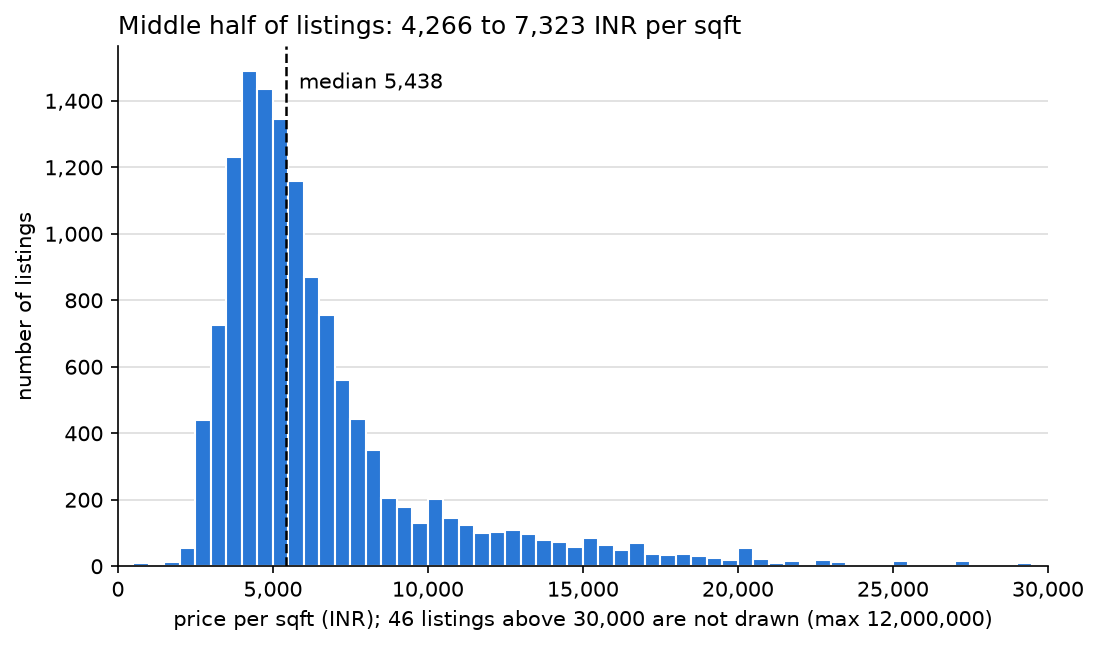

In [27]:
CAP = 30_000    # the x-axis stops here so the bulk of the data is readable; rows above it stay in the data
n_beyond = int((pps > CAP).sum())

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.hist(pps, bins=60, range=(0, CAP), color="#2a78d6", edgecolor="white")
ax.axvline(pps.median(), color="black", linestyle="--", linewidth=1.2)
ax.text(pps.median() + 400, ax.get_ylim()[1] * 0.95, f"median {pps.median():,.0f}", va="top")

ax.set_title(f"Middle half of listings: {pps.quantile(0.25):,.0f} to {pps.quantile(0.75):,.0f} INR per sqft", loc="left")
ax.set_xlabel(f"price per sqft (INR); {n_beyond} listings above {CAP:,} are not drawn (max {pps.max():,.0f})")
ax.set_ylabel("number of listings")
ax.set_xlim(0, CAP)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")   # thousands separators on the tick labels
ax.yaxis.set_major_formatter(lambda y, pos: f"{y:,.0f}")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#dddddd")
ax.set_axisbelow(True)
plt.show()

In [28]:
# Extreme values: reported, not removed.
cols = ["location", "total_sqft", "bath", "price", "bhk", "price_per_sqft"]
print("Highest price_per_sqft:")
display(df2.nlargest(5, "price_per_sqft")[cols].round(1))
print("Lowest price_per_sqft:")
display(df2.nsmallest(5, "price_per_sqft")[cols].round(1))
print("Highest bhk:")
display(df2.nlargest(5, "bhk")[cols].round(1))
print(f"price_per_sqft below 1,000: {(pps < 1000).sum()} rows | above 20,000: {(pps > 20000).sum()} rows")

Highest price_per_sqft:


,location,total_sqft,bath,price,bhk,price_per_sqft
4086,Sarjapur Road,1.0,4.0,120.0,4,12000000.0
4972,Srirampuram,5.0,7.0,115.0,7,2300000.0
349,Suragajakkanahalli,11.0,3.0,74.0,3,672727.3
1122,Grihalakshmi Layout,24.0,2.0,150.0,5,625000.0
11558,Whitefield,60.0,4.0,218.0,4,363333.3


Lowest price_per_sqft:


,location,total_sqft,bath,price,bhk,price_per_sqft
1894,Nelamangala,52272.0,2.0,140.0,3,267.8
674,Yelahanka,35000.0,3.0,130.0,3,371.4
7520,Doddaballapur,11840.3,2.0,48.0,3,405.4
5393,Doddabommasandra,42000.0,8.0,175.0,9,416.7
3228,Dodda Banaswadi,32722.3,5.0,140.0,5,427.8


Highest bhk:


,location,total_sqft,bath,price,bhk,price_per_sqft
4684,Munnekollal,2400.0,40.0,660.0,43,27500.0
1718,2Electronic City Phase II,8000.0,27.0,230.0,27,2875.0
3379,1Hanuman Nagar,2000.0,16.0,490.0,19,24500.0
11559,1Kasavanhalli,1200.0,18.0,200.0,18,16666.7
3609,Koramangala Industrial Layout,10000.0,16.0,550.0,16,5500.0


price_per_sqft below 1,000: 17 rows | above 20,000: 238 rows


**What this shows**

- **The × 100,000 conversion is right.** The median is 5,438 INR per sqft and the middle half runs from 4,266 to 7,323: thousands of INR, as a Bengaluru flat should be. Leaving out the × 100,000 would give values near 0.05.
- **Long right tail.** The mean (7,923) sits well above the median, and 238 rows are above 20,000 (the 99th percentile is 23,740).
- **Implausible values at both ends.** 17 rows are below 1,000 INR per sqft. Eleven of them are plot-sized (11,840 to 52,272 sqft). The other six span 1,798 to 10,961 sqft, and two of those are ordinary home sizes with prices that look too low (BTM Layout: 1,798 sqft at 10 lakh; Begur: 2,400 sqft at 12 lakh). That is a different problem from the plots, and a rule on area would not catch it. The highest values come from tiny `total_sqft` entries: 1, 5, 11, 24 and 60 sqft for homes with 3 to 7 bedrooms, such as 120 lakh for 1 sqft = 12,000,000 INR per sqft. A few rows like these are why the standard deviation (106,601) is more than 13 times the mean.
- **Extreme `bhk`.** 26 rows have 10 or more bedrooms; the top five are 43, 27, 19, 18 and 16. The 43-bedroom row has 2,400 sqft and 40 bathrooms. Three of the five locations begin with a digit ("2Electronic City Phase II", "1Hanuman Nagar", "1Kasavanhalli"), which is a location-cleaning question for Session 3.
- **Converted unit rows.** Their median (4,855) is close to the overall median, so the two factors look right. Two of the five lowest values are large Sq. Meter plots (1,100 and 3,040 sq m), and the highest of the 32 is a 45 Sq. Yards listing with 6 bathrooms (98,765).

All of these rows are left in. Deciding which ones are real outliers is Session 4's job.

### Step 5. Drop `size`, then check the final frame

`size` is replaced by `bhk`, so it goes last, once the assertion in Step 1 has confirmed that `bhk` is complete. The assertion is repeated just before the drop.

In [29]:
assert df2["bhk"].notna().all()            # bhk is complete, so `size` is no longer needed
df2 = df2.drop(columns="size")

assert list(df2.columns) == ["location", "total_sqft", "bath", "price", "bhk", "price_per_sqft"]
assert df2.isnull().sum().sum() == 0
assert pd.api.types.is_float_dtype(df2["total_sqft"]) and pd.api.types.is_integer_dtype(df2["bhk"])

print(f"Final Session 2 shape: {df2.shape}")
display(df2.dtypes.to_frame("dtype").T)
df2.head()

Final Session 2 shape: (13232, 6)


,location,total_sqft,bath,price,bhk,price_per_sqft
dtype,str,float64,float64,float64,int64,float64


,location,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,1200.0,2.0,51.00,2,4250.000000


## Session 3: location cleaning and dimensionality reduction

**Objective.** Reduce `location` from about 1,300 raw names to roughly 240 real locations plus one `other` bucket, with a documented threshold.

**Why.** One-hot encoding (Session 5) turns every distinct location into a column. With about 1,300 locations and 13,000 rows, most of those columns would be nearly empty and the model could not learn from them. Grouping rare locations keeps the feature matrix small.

**Cautions for the whole session**

- No rows are removed (asserted below); duplicates and outliers are still left in.
- `other` is a catch-all, not a place. It will hold about a fifth of the rows, and Session 6 decides how the website treats it.
- The threshold is a convention. Session 5 will test whether a different one changes the cross-validation score.
- Listing counts are computed on all rows, before the train/test split. That is a known limitation (see the README).
- `price_per_sqft` stays out of the features.

In [30]:
# Work on a copy: df2 (the Session 2 result) stays untouched.
df3 = df2.copy()
df3.shape

(13232, 6)

### Step 1. Normalize the names

Three clean-ups, in this order:

1. **Whitespace.** `str.split()` cuts a name at every run of whitespace (and drops the ends), and `str.join(" ")` glues the words back with a single space. This fixes "Sarjapur  Road" (two spaces).
2. **Case.** A casefolded copy of each name is the key, so "JP Nagar" and "jp nagar" count as one place.
3. **Trailing punctuation.** Names such as "Kudlu Village," end in a comma. The cell below shows which characters actually end names, so the clean-up covers what is there.

Each key then gets its most frequent spelling as the clean name, so the website can later show readable names ("JP Nagar", not "jp nagar").

In [31]:
# Strip and collapse whitespace: split() cuts at every run of whitespace and drops the ends,
# join(" ") glues the words back together with a single space.
ws = df3["location"].str.split().str.join(" ")

# Which characters end a name when they are not a letter or a digit? (counted in rows)
last_char = ws.str[-1]
last_char[~last_char.str.isalnum()].value_counts()

location
,    56
.     3
)     1
Name: count, dtype: int64

The commas (56 rows) and periods (3 rows) are trailing punctuation. The single `)` closes a bracket in "Kengeri Satellite Town ( BDA SITE)" and belongs to the name, so only commas, periods and the spaces in front of them are removed.

In [32]:
stripped = ws.str.rstrip(" ,.")                # remove trailing commas, periods and the spaces in front of them
assert (stripped.str.len() > 0).all()          # no name has become empty
key = stripped.str.casefold()                  # one key per place, whatever the capitalisation

# Each key gets its most frequent spelling as the clean name; transform() puts that spelling on every row of the key.
# If two spellings tie, mode() lists them in sorted order, so the pick is the same on every run.
df3["location"] = stripped.groupby(key).transform(lambda spellings: spellings.mode().iloc[0])
assert df3["location"].nunique() == key.nunique()      # exactly one clean name per key

n_spellings = stripped.groupby(key).nunique()          # how many spellings each key has
multi = n_spellings[n_spellings > 1].index
print(f"rows changed by the trailing-punctuation step: {(ws != stripped).sum()}")
print(f"{len(multi)} places are written in more than one way; the busiest has {key.value_counts().loc[multi].max()} listings")

rows changed by the trailing-punctuation step: 59
12 places are written in more than one way; the busiest has 9 listings


In [33]:
# Distinct names after each clean-up, and how the names split at 10 listings.
stages = {
    "raw": df2["location"],
    "strip + collapse whitespace": ws,
    "+ casefold": ws.str.casefold(),
    "+ trailing punctuation removed": key,
}
funnel = []
for step, names in stages.items():
    n = names.value_counts()                   # listings per name
    funnel.append({
        "step": step,
        "distinct names": len(n),
        "> 10: names": int((n > 10).sum()),
        "> 10: rows": int(n[n > 10].sum()),
        "<= 10: names": int((n <= 10).sum()),
        "<= 10: rows": int(n[n <= 10].sum()),
        "<= 10: % of rows": round(n[n <= 10].sum() / len(names) * 100, 1),
        "1 listing: names": int((n == 1).sum()),
    })
pd.DataFrame(funnel).set_index("step")

,distinct names,> 10: names,> 10: rows,<= 10: names,<= 10: rows,<= 10: % of rows,1 listing: names
step,,,,,,,
raw,1299,240,10334,1059,2898,21.9,476
strip + collapse whitespace,1288,240,10349,1048,2883,21.8,469
+ casefold,1276,240,10349,1036,2883,21.8,453
+ trailing punctuation removed,1266,240,10364,1026,2868,21.7,447


**What the clean-up did.** The distinct names fall from 1,299 to 1,288 (whitespace), 1,276 (case) and 1,266 (trailing punctuation). The number of locations with more than 10 listings stays at 240 at every stage, so the clean-up never changes which locations are named; it only moves rows into them, and the share of rows in locations with 10 or fewer listings goes from 21.9% to 21.7%. Case merging reduces the names but moves no rows across the threshold: the 12 places written in more than one way all have 9 or fewer listings.

Up to the case step the numbers are the brief's expected findings exactly: 240 locations with more than 10 listings covering 10,349 rows, 1,036 locations with 10 or fewer covering 2,883 rows (21.8%), and 453 locations with a single listing. The trailing-punctuation step moves 15 more rows into named locations (Sarjapur Road gains 8 and Whitefield 2), so the biggest locations below are Whitefield 537 and Sarjapur Road 400 where the brief had 535 and 392. The other three match: Electronic City 304, Kanakpura Road 264, Thanisandra 236.

### Step 2. Count listings per location

How many locations have 1, up to 5, up to 10 and up to 20 listings, and what share of the rows each threshold would move into `other`.

In [34]:
counts = df3["location"].value_counts()          # listings per clean location
print("Biggest locations:", counts.head(5).to_dict())

threshold_rows = []
for t in [1, 5, 10, 20]:
    small = counts[counts <= t]                  # the locations at or below the threshold
    threshold_rows.append({
        "threshold": f"<= {t}",
        "locations at or below": len(small),
        "named locations kept": len(counts) - len(small),
        "rows moved to other": int(small.sum()),
        "% of rows": round(small.sum() / len(df3) * 100, 1),
    })
pd.DataFrame(threshold_rows).set_index("threshold")

Biggest locations: {'Whitefield': 537, 'Sarjapur Road': 400, 'Electronic City': 304, 'Kanakpura Road': 264, 'Thanisandra': 236}


,locations at or below,named locations kept,rows moved to other,% of rows
threshold,,,,
<= 1,447,819,447,3.4
<= 5,880,386,1763,13.3
<= 10,1026,240,2868,21.7
<= 20,1123,143,4280,32.3


### Step 3. Pick a threshold and replace rare locations with `other`

**Decision: locations with 10 or fewer listings become `other`.** That is 1,026 of the 1,266 names and 2,868 rows (21.7%); the 240 locations with 11 or more listings keep their names, which makes 241 categories with `other`. A location with 10 listings gives the model at most 10 examples to learn from (fewer once rows are held out for testing), too few to estimate a location effect.

The alternatives in the table above: threshold 5 keeps 386 named locations (146 more columns once the locations are one-hot encoded) and moves 13.3% of the rows; threshold 20 keeps 143 and moves 32.3%, so nearly a third of the listings would lose their location; threshold 1 (only single listings) keeps 819 locations and moves 3.4%. Ten is the brief's default and a convention; Session 5 will test whether another value changes the cross-validation score.

In [35]:
THRESHOLD = 10
OTHER = "other"
assert OTHER not in counts.index                         # no real location is called "other"

listings = df3["location"].map(counts)                   # listings of each row's location, repeated on every row
df3.loc[listings <= THRESHOLD, "location"] = OTHER

n_named = int((counts > THRESHOLD).sum())
n_other = int((df3["location"] == OTHER).sum())
assert len(df3) == 13_232                                # no rows removed
assert list(df3.columns) == list(df2.columns)            # columns unchanged
assert df3["location"].notna().all()
assert df3["location"].nunique() == n_named + 1          # the named locations plus "other"

print(f"threshold {THRESHOLD}: {n_named} named locations + '{OTHER}' = {df3['location'].nunique()} categories")
print(f"'{OTHER}' holds {n_other:,} of {len(df3):,} rows ({n_other / len(df3):.1%})")
df3["location"].value_counts().head(6).to_frame("rows")

threshold 10: 240 named locations + 'other' = 241 categories
'other' holds 2,868 of 13,232 rows (21.7%)


,rows
location,
other,2868
Whitefield,537
Sarjapur Road,400
Electronic City,304
Kanakpura Road,264
Thanisandra,236


### Step 4. `other` compared with the named locations

Median `price_per_sqft` (INR) of the rows in `other` against all rows in named locations, with the quartiles for the spread.

In [36]:
is_other = df3["location"] == OTHER
by_group = df3.groupby(is_other)["price_per_sqft"].describe()[["count", "25%", "50%", "75%"]].round(0).astype(int)
by_group.index = ["named locations", "other"]      # groupby sorts False before True
by_group

,count,25%,50%,75%
named locations,10364,4221,5333,6978
other,2868,4444,5908,10000


**What this shows.** The median `price_per_sqft` of `other` is 5,908 INR against 5,333 for the named locations (10.8% higher), and its spread is much wider: the middle half of `other` runs from 4,444 to 10,000, against 4,221 to 6,978. With 2,868 rows, `other` is also the largest category, more than five times the largest named location (Whitefield, 537). It is a catch-all of many unrelated places, not a place: knowing that a listing is in `other` says little about its price. Session 6 decides how the website treats it.

### Step 5. Digit-glued names

Names such as "1Hanuman Nagar" and "2Electronic City Phase II" have a digit directly in front of a letter. Ordinals ("1st", "7th") also have that shape but are legitimate, so they are excluded. The names are listed, not edited.

In [37]:
# A digit directly followed by a letter, unless the letters are an ordinal suffix (1st, 2nd, 3rd, 7th).
# (?i) ignores case, \d is a digit, (?!...) means "not followed by", \b is a word boundary.
glued_pattern = r"(?i)\d(?!(?:st|nd|rd|th)\b)[a-z]"
glued = counts[counts.index.str.contains(glued_pattern)]       # clean name -> listings
print(f"{len(glued)} names match, covering {glued.sum()} rows ({glued.sum() / len(df3):.2%} of all rows)")
print(f"most listings of any of them: {glued.max()} (threshold {THRESHOLD}), so {int((glued > THRESHOLD).sum())} survive")

# Context: all names that start with a digit.
starts_with_digit = counts[counts.index.str.match(r"\d")]
ordinal = starts_with_digit.index.str.match(r"(?i)\d+(st|nd|rd|th)\b")
print(f"{len(starts_with_digit)} names start with a digit; {ordinal.sum()} are ordinals like '7th Phase JP Nagar'; "
      f"{int((starts_with_digit[ordinal] > THRESHOLD).sum())} of those survive the threshold")

# The matching rows. df3 now shows `other` in `location`, so the cleaned name is added as `name`.
glued_rows = df3.assign(name=stripped)[stripped.isin(glued.index)]
glued_rows[["name", "location", "bhk", "bath", "total_sqft", "price"]]

9 names match, covering 9 rows (0.07% of all rows)
most listings of any of them: 1 (threshold 10), so 0 survive
62 names start with a digit; 51 are ordinals like '7th Phase JP Nagar'; 10 of those survive the threshold


,name,location,bhk,bath,total_sqft,price
1718,2Electronic City Phase II,other,27,27.0,8000.0,230.0
3379,1Hanuman Nagar,other,19,16.0,2000.0,490.0
4105,Indranagar 100ft road defence colony,other,5,5.0,5800.0,80.0
4916,1Channasandra,other,14,15.0,1250.0,125.0
6034,1A Block Koramangala,other,4,4.0,2360.0,650.0
6621,BTM Layout 1stage 9th Main,other,7,6.0,600.0,138.0
7568,bsk 6th stage 2ad block near sri conversation ...,other,4,4.0,600.0,87.0
9935,1Hoysalanagar,other,13,13.0,5425.0,275.0
11559,1Kasavanhalli,other,18,18.0,1200.0,200.0


**What this shows**

- **Nine names match, covering 9 rows (0.07% of the data), with one listing each, so none survives the threshold.** All nine rows are in `other`, and no name was edited by hand.
- **Six of the nine start with a digit** (the pattern in the brief). Five of those six also have an extreme bedroom count: `bhk` 13 to 27 with a bathroom count close to it (for example "2Electronic City Phase II": 27 bedrooms, 27 bathrooms). Together with the digit glued to the name, these look like bad rows rather than just misnamed places; whether to remove them is a question for Session 4. The sixth, "1A Block Koramangala" (4 bedrooms), is a real block name.
- **The other three have a digit inside the name**: "100ft", "1stage" and "2ad". Their bedroom counts (4 to 7) are ordinary, and they look like free text with typos rather than leaked digits.
- **Digit-leading names in general.** 62 names start with a digit; 51 are ordinals such as "7th Phase JP Nagar", and 10 of those survive the threshold (the other 41 have 10 or fewer listings and go to `other`). The remaining 11 are the six glued names above plus five written with a space after the digit ("1 Giri Nagar", "1 Ramamurthy Nagar", "1 Annasandrapalya", "1 Immadihalli", "4 Bedroom Farm House in Bagalur"). Those five do not match the brief's rule, have one listing each, and also fall into `other`.

## Session 4: duplicates and outlier removal

**Objective.** Remove repeated listings and implausible rows with rules that each have a stated reason, a count and a look at the rows they remove, and finish with a frame that is fit for modeling.

**The rules, in this order**

1. **Repeats**: rows that repeat an earlier row on all nine raw columns.
2. **Domain rules**: fewer than 300 sqft per bedroom, and more than `bhk + 2` bathrooms.
3. **Per-location fences**: `price_per_sqft` outside the IQR fences of its own location (locations with 10 or more rows).
4. **Pooled fence**: one IQR fence for all the rows in places with fewer than 10 rows.

**Why this order.** Quartiles and fences are computed from whatever rows are present when a rule runs. A repeated row counts twice in every quartile, and a garbage row (120 lakh for 1 sqft) drags up the fences of its location. So the repeats go first, then the domain rules that remove impossible rows, and only then the fences. Rule 3 measures the effect.

**Cautions for the whole session**

- Every rule is counted, and 10 random removed rows per rule are printed so the rule can be checked by eye.
- Nothing is edited to rescue a row: a row is kept or removed.
- The fences use the cleaned location names (`location_clean`), never the grouped `location`: its `other` bucket mixes many unrelated places, so a fence over it would mean nothing.
- `price_per_sqft` stays in the frame until the first step of Session 5. It is built from the target, so it must never be a model input.
- The rules run on all rows before the train/test split, which is a known limitation (see the README).

In [38]:
import numpy as np

# Work on a copy: df3 (the Session 3 result) stays untouched, so "before" is still available for the figures.
df4 = df3.copy()
assert df4.shape == (13_232, 6)

SEED = 42          # every random sample below uses this seed, so the same rows come up on every run
MIN_ROWS = 10      # a location needs at least this many rows to get its own fences (Rule 3)

# The cleaned location names from before the rare ones became "other". Session 3 overwrote them in df3,
# so they are rebuilt here with the same steps, as a separate Series aligned to the frame by row label.
# Fences and counts below use this Series, never the grouped df4["location"].
cleaned = df2["location"].str.split().str.join(" ").str.rstrip(" ,.")
location_clean = cleaned.groupby(cleaned.str.casefold()).transform(lambda spellings: spellings.mode().iloc[0])

kept_name = df3["location"] != OTHER
assert location_clean.nunique() == 1_266                                            # the 1,266 names of Session 3
assert (location_clean[kept_name] == df3.loc[kept_name, "location"]).all()          # same name wherever Session 3 kept a name
print(f"'{OTHER}' mixes {location_clean[~kept_name].nunique():,} different places in {(~kept_name).sum():,} rows")

# How expensive is a row's neighbourhood? The median price_per_sqft of its location, over the 13,232 rows.
location_level = df3["price_per_sqft"].groupby(location_clean).transform("median")

'other' mixes 1,026 different places in 2,868 rows


In [39]:
R_REPEATS = "repeated rows (all nine raw columns)"
R_AREA = "fewer than 300 sqft per bedroom"
R_BATH = "more than bhk + 2 bathrooms"
R_LOCATION = "outside the fences of its location"
R_POOLED = "outside the pooled fence (small locations)"

steps = []       # one entry per rule; the waterfall table is built from it
removed = {}     # the rows each rule removes, kept for the samples and for the comparison with the survivors


def apply_rule(frame, rule, flag):
    """Remove the rows where `flag` is True. The rows go to `removed`, the counts to `steps`."""
    removed[rule] = frame[flag]
    steps.append({"rule": rule, "rows before": len(frame), "removed": int(flag.sum()), "rows after": int((~flag).sum())})
    return frame[~flag]


def look(rule, **extra):
    """10 random removed rows (all of them if the rule removed fewer). The clean name replaces the grouped location."""
    rows = removed[rule]
    rows = rows.sample(min(10, len(rows)), random_state=SEED).sort_index()
    return rows.assign(location=location_clean, location_median_pps=location_level, **extra).round(1)


def places_by_rows(rows):
    """The clean place names of these rows, most rows first. Equal counts stay in alphabetical order, so the order does not depend on the pandas version."""
    return location_clean[rows.index].value_counts().sort_index().sort_values(ascending=False, kind="stable")

### Rule 1. Repeated listings

**Reason.** A listing that appears twice would land on both sides of the train/test split, so the model would be scored on rows it has already seen, and every quartile below would count it twice.

**Test.** `df_raw.duplicated()` on all nine raw columns. With `keep="first"` the first copy stays and every later copy is flagged. The nine raw columns are the right test: on the five columns the frame kept, two different flats of the same size at the same price in the same place look identical, although `society`, `area_type`, `availability` or `balcony` can tell them apart. The drops in Sessions 1 and 2 kept the raw row labels, so the flags are matched to the frame by index.

In [40]:
repeat_flag = df_raw.duplicated()                                    # all nine raw columns; every copy after the first is True
assert (df3["price"] == df_raw.loc[df3.index, "price"]).all()        # df3 still carries the raw row labels, so matching by index is valid
is_repeat = repeat_flag.loc[df3.index]                               # match to our frame by row label

print(f"repeated rows in the raw data: {repeat_flag.sum()} | inside the Session 3 frame: {is_repeat.sum()}")
five = ["location", "total_sqft", "bath", "price", "bhk"]            # the five kept columns (location as it was before Session 3)
print(f"judged on those five columns the count would be {df2.duplicated(subset=five).sum()}, "
      f"which includes flats that differ in society, area_type, availability or balcony")

# How many copies does each repeated listing have?
rows_per_listing = df_raw.value_counts(dropna=False)                 # identical raw rows are counted together
rows_per_listing[rows_per_listing > 1].value_counts().sort_index().rename_axis("copies").to_frame("listings").T

repeated rows in the raw data: 529 | inside the Session 3 frame: 529
judged on those five columns the count would be 888, which includes flats that differ in society, area_type, availability or balcony


copies,2,3,4,5,6,7,9,10
listings,301,49,13,7,4,3,2,1


In [41]:
df4 = apply_rule(df4, R_REPEATS, is_repeat)
print(f"rows: {len(df3):,} -> {len(df4):,}")

# Look at what was removed: 10 random rows in their raw form, with the row label of the copy that stays
# and the number of identical rows in all (the kept one included).
by_listing = df_raw.reset_index().groupby(list(df_raw.columns), dropna=False)["index"]
first_copy = by_listing.transform("min")
n_copies = by_listing.transform("size")
assert first_copy.index.equals(df_raw.index)

sample = removed[R_REPEATS].sample(10, random_state=SEED).sort_index()
df_raw.loc[sample.index].assign(kept_copy=first_copy, copies=n_copies)

rows: 13,232 -> 12,703


,area_type,availability,location,size,society,total_sqft,bath,balcony,price,kept_copy,copies
1477,Super built-up Area,Ready To Move,Uttarahalli,3 BHK,Aklia R,1330,2.0,1.0,56.00,1096,2
5097,Super built-up Area,19-Jun,Hebbal,4 BHK,Raard B,2790,4.0,3.0,198.00,1840,3
5682,Super built-up Area,Ready To Move,Budigere,3 BHK,PrityTr,1820,3.0,2.0,93.00,4135,2
6513,Super built-up Area,19-Dec,Marathahalli,3 BHK,PrensKe,1469,3.0,1.0,89.00,1626,2
8607,Super built-up Area,19-Jul,Kanakpura Road,3 BHK,Soazak,1592,3.0,NaN,125.00,2248,2
10183,Super built-up Area,Ready To Move,HSR Layout,2 BHK,NRosete,1140,2.0,2.0,46.00,1052,9
10474,Super built-up Area,18-Sep,Chandapura,2 BHK,SunceEs,1015,2.0,2.0,25.88,887,2
11465,Super built-up Area,Ready To Move,7th Phase JP Nagar,3 BHK,Eladero,1575,2.0,2.0,110.00,2963,2
12853,Super built-up Area,Ready To Move,Yelahanka,3 BHK,Pyikad,1282,2.0,1.0,48.72,7601,2
13271,Super built-up Area,Ready To Move,Uttarahalli,2 BHK,Ayaya A,1075,2.0,1.0,46.76,7102,2


**What this shows**

- **All 529 repeats are in the frame, and 12,703 rows are left.** None had been dropped in Sessions 1 or 2: identical rows share the columns those drops looked at, so they were kept or dropped together.
- **Nine columns, not five.** On the five kept columns the count would be 888, which is 359 more. Those 359 rows match another row in location, area, bathrooms, price and bedrooms but differ in `society`, `area_type`, `availability` or `balcony`, so they can be different flats.
- **380 listings repeat**: 301 appear twice, 49 three times, and the most repeated has 10 copies. Each sampled row has an identical earlier row (`kept_copy`, always a lower row label).
- **What the rule cannot tell.** The data has no listing id, so one flat posted twice and two identical flats in one project at one price look the same. A few real flats may be lost; one copy of each always stays. Session 5 can compare scores with and without the repeats.
- **Who loses rows.** The comparison at the end of the session shows that the removed rows are ordinary for their location (price per sqft 0.99 times the location median) and a little cheaper than the survivors (median price 55 lakh against 68). They sit in a few places: Haralur Road 40, Uttarahalli 29, Kanakpura Road 24, Sarjapur Road 20.

### Rule 2. Domain rules

**Reason.** Two things no price can rescue. A bedroom needs floor area, so a listing with fewer than 300 sqft per bedroom (`total_sqft / bhk`) has a wrong area or a wrong bedroom count; this is the rule that catches the 1 to 60 sqft entries and the 43-bedroom row on 2,400 sqft. And a home does not have more than two bathrooms beyond its bedrooms (`bath > bhk + 2`).

Both thresholds are conventions, so the table shows what 250 and 350 would do. The rule looks at area and bedrooms, not at price, so it can remove a real home along with the wrong rows; the median `price_per_sqft` of the flagged rows is in the table for that reason.

In [42]:
too_many_baths = df4["bath"] > df4["bhk"] + 2

rows = []
for per_bedroom in [250, 300, 350]:
    too_small = df4["total_sqft"] / df4["bhk"] < per_bedroom
    flagged = too_small | too_many_baths                  # composing two masks: a row is flagged if either rule hits it
    rows.append({
        "sqft per bedroom below": per_bedroom,
        "area rule alone": int(too_small.sum()),
        "area or bathroom rule": int(flagged.sum()),
        "% of rows": round(flagged.mean() * 100, 1),
        "median price_per_sqft of the flagged rows": round(df4.loc[flagged, "price_per_sqft"].median()),
    })
display(pd.DataFrame(rows).set_index("sqft per bedroom below"))
print(f"median price_per_sqft of all {len(df4):,} rows: {df4['price_per_sqft'].median():,.0f}")

,area rule alone,area or bathroom rule,% of rows,median price_per_sqft of the flagged rows
sqft per bedroom below,,,,
250,605,616,4.8,13333
300,737,746,5.9,12500
350,1086,1095,8.6,11733


median price_per_sqft of all 12,703 rows: 5,484


In [43]:
# The brief measured its counts on all 13,232 rows, repeats still in. The same rules on that basis:
a = df3["total_sqft"] / df3["bhk"] < 300
b = df3["bath"] > df3["bhk"] + 2
print(f"all {len(df3):,} rows: {a.sum()} under 300 sqft per bedroom + {b.sum()} with more than bhk + 2 bathrooms "
      f"- {(a & b).sum()} in both = {(a | b).sum()} ({(a | b).mean():.1%})")

too_small = df4["total_sqft"] / df4["bhk"] < 300
print(f"after Rule 1 ({len(df4):,} rows): {too_small.sum()} + {too_many_baths.sum()} - {(too_small & too_many_baths).sum()} in both "
      f"= {(too_small | too_many_baths).sum()} ({(too_small | too_many_baths).mean():.1%})")

df4 = apply_rule(df4, R_AREA, too_small)
df4 = apply_rule(df4, R_BATH, df4["bath"] > df4["bhk"] + 2)    # recomputed: the rows the first rule did not already take
print(f"rows: {steps[0]['rows after']:,} -> {len(df4):,}")

print("\nRemoved by the area rule (10 random rows):")
display(look(R_AREA, sqft_per_bedroom=df3["total_sqft"] / df3["bhk"]))

area_rows = removed[R_AREA]
print(f"the area rule's {len(area_rows)} rows: {(area_rows['bhk'] >= 4).sum()} have 4 or more bedrooms (median {area_rows['bhk'].median():.0f}), "
      f"the median is {(area_rows['total_sqft'] / area_rows['bhk']).median():.0f} sqft per bedroom, {(area_rows['total_sqft'] <= 100).sum()} have 100 sqft or less")
print(f"exactly 1,200 sqft: {(area_rows['total_sqft'] == 1200).sum()} of them ({(area_rows['total_sqft'] == 1200).mean():.0%}), "
      f"against {(df3['total_sqft'] == 1200).mean():.1%} of all rows\n")

print("Removed by the bathroom rule (all of them, there are fewer than 10):")
display(look(R_BATH, bath_minus_bhk=df3["bath"] - df3["bhk"]))

all 13,232 rows: 747 under 300 sqft per bedroom + 16 with more than bhk + 2 bathrooms - 7 in both = 756 (5.7%)
after Rule 1 (12,703 rows): 737 + 16 - 7 in both = 746 (5.9%)
rows: 12,703 -> 11,957

Removed by the area rule (10 random rows):


,location,total_sqft,bath,price,bhk,price_per_sqft,location_median_pps,sqft_per_bedroom
727,Jeevan bima nagar,1210.0,4.0,160.0,5,13223.1,12703.3,242.0
807,HBR Layout,675.0,3.0,59.0,4,8740.7,7938.2,168.8
3523,Jigani,1200.0,10.0,105.0,10,8750.0,5330.6,120.0
4714,Nagarbhavi,1200.0,4.0,240.0,5,20000.0,7619.0,240.0
9869,Bagalakunte,750.0,3.0,95.0,5,12666.7,8928.0,150.0
9909,Uttarahalli,1200.0,6.0,330.0,6,27500.0,4058.5,200.0
10327,Govindapura,702.0,4.0,65.0,4,9259.3,6717.6,175.5
10386,M V Extenstion,900.0,5.0,135.0,5,15000.0,13055.6,180.0
10981,Hosa Road,900.0,5.0,55.0,5,6111.1,5072.0,180.0
12215,Banaswadi,1200.0,6.0,220.0,6,18333.3,5397.9,200.0


the area rule's 737 rows: 600 have 4 or more bedrooms (median 5), the median is 200 sqft per bedroom, 7 have 100 sqft or less
exactly 1,200 sqft: 173 of them (23%), against 6.4% of all rows

Removed by the bathroom rule (all of them, there are fewer than 10):


,location,total_sqft,bath,price,bhk,price_per_sqft,location_median_pps,bath_minus_bhk
1078,BTM 1st Stage,3300.0,14.0,500.0,9,15151.5,14166.7,5.0
2620,Sathya Sai Layout,11338.0,9.0,1000.0,6,8819.9,9370.9,3.0
6838,Rajaji Nagar,7500.0,8.0,1700.0,5,22666.7,13980.9,3.0
7709,Chikkabanavar,2460.0,7.0,80.0,4,3252.0,4041.7,3.0
9974,Sector 1 HSR Layout,2400.0,6.0,775.0,3,32291.7,9104.3,3.0
11366,Nagasandra,7000.0,8.0,450.0,4,6428.6,6247.6,4.0
12103,Thanisandra,1806.0,6.0,116.0,3,6423.0,5706.6,3.0
12443,Dollars Colony,4350.0,8.0,2600.0,4,59770.1,11209.7,4.0
13067,Defence Colony,7150.0,13.0,3600.0,10,50349.7,13543.3,3.0


**What this shows**

- **The counts match the brief's measurement.** On all 13,232 rows the area rule flags 747 rows and the bathroom rule 16; 7 rows fail both, so 756 (5.7%) fail at least one. With the repeats gone the counts are 737, 16 and 746 (5.9% of 12,703). The bathroom rule adds only 9 rows to what the area rule takes.
- **300 sits on a slope, not at a boundary in the data.** 250 would keep 132 of the 737 rows; 350 would remove 349 more (1,095 rows, 8.6%). The flagged rows have a much higher `price_per_sqft` than the rest at every threshold (median 13,333, 12,500 and 11,733 against 5,484), so even the extra rows at 350 are unusual. The threshold stays at 300, the brief's value.
- **The area rule mostly removes many-bedroom houses.** 600 of its 737 rows have 4 or more bedrooms (median 5, with a median of 200 sqft per bedroom), and only 7 have 100 sqft or less. 173 of them (23%) are exactly 1,200 sqft, against 6.4% of all rows. 1,200 sqft is the size of a 30 × 40 ft site, which suggests that for many of these houses `total_sqft` is the site and not the floor area. They are probably real homes whose area does not mean what it means for a flat. The cost is that the model sees fewer large houses.
- **The bathroom rule takes 9 rows, mostly large, expensive homes.** The median price is 775 lakh and the median area 4,350 sqft; 7 of the 9 cost 300 lakh or more, and the dearest is 3,600 lakh. It is a small cut (0.07% of the rows), but it is a rule that can remove a real home.

### Rule 3. Per-location fences on `price_per_sqft`

**Reason.** A price per sqft that is far outside what its own neighbourhood charges is more likely a data error than a home: a "price" that is really a rent, a "total_sqft" that is really a plot. What counts as far depends on the place, so each location gets its own fences, `Q1 − 1.5 × IQR` and `Q3 + 1.5 × IQR`, where Q1 and Q3 are the quartiles of the location's `price_per_sqft` and IQR = Q3 − Q1.

**Why quartiles and not the mean and standard deviation.** The mean and the SD are pulled by the very outliers the fence is meant to find, and a cut at mean ± 1 SD removes about a third of the rows of any normal distribution by construction. Quartiles hardly move when a few extreme rows are added. The cell after the rule counts what mean ± 1 SD would flag on the same rows.

**Which locations.** Only cleaned names with 10 or more rows left at this point get their own fences: quartiles from fewer rows say little. (Session 3 asked for more than 10 listings to keep a name; here 10 rows are enough to estimate quartiles, as the brief says.) The rows of all other places are handled by the pooled fence (Rule 4). The fences use `location_clean`, and the rows counted are the ones left after Rules 1 and 2.

In [44]:
def location_fences(frame, loc):
    """For every row: its clean location, whether that location has MIN_ROWS rows or more, and the IQR fences of the location."""
    loc = loc.loc[frame.index]
    price_sqft = frame["price_per_sqft"]
    # transform() computes one number per location and repeats it on every row of that location
    q1 = price_sqft.groupby(loc).transform(lambda s: s.quantile(0.25))
    q3 = price_sqft.groupby(loc).transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return pd.DataFrame({
        "location": loc,
        "tested": loc.map(loc.value_counts()) >= MIN_ROWS,
        "lower": q1 - 1.5 * iqr,
        "upper": q3 + 1.5 * iqr,
    })


fences = location_fences(df4, location_clean)       # on the rows left after Rules 1 and 2
price_sqft = df4["price_per_sqft"]
below = fences["tested"] & (price_sqft < fences["lower"])
above = fences["tested"] & (price_sqft > fences["upper"])
flag_location = below | above                       # rows of locations that are not tested can never be flagged here

n_tested = int(fences["tested"].sum())
print(f"locations with {MIN_ROWS} or more rows: {fences.loc[fences['tested'], 'location'].nunique()} ({n_tested:,} of {len(df4):,} rows); "
      f"the other {len(df4) - n_tested:,} rows go to the pooled fence")
print(f"rows flagged: {flag_location.sum()} ({flag_location.sum() / len(df4):.1%} of all rows, {flag_location.sum() / n_tested:.1%} of the rows tested): "
      f"{below.sum()} below the lower fence, {above.sum()} above the upper fence")

per_location = fences[fences["tested"]].groupby("location")[["lower", "upper"]].first()     # one row of fences per tested location
print(f"locations whose lower fence is below zero, so no row there can fall under it: {(per_location['lower'] < 0).sum()} of {len(per_location)}")

locations with 10 or more rows: 230 (9,368 of 11,957 rows); the other 2,589 rows go to the pooled fence
rows flagged: 575 (4.8% of all rows, 6.1% of the rows tested): 56 below the lower fence, 519 above the upper fence
locations whose lower fence is below zero, so no row there can fall under it: 28 of 230


In [45]:
# Why not mean +/- 1 SD? What it would flag on the same rows:
group_mean = price_sqft.groupby(fences["location"]).transform("mean")
group_sd = price_sqft.groupby(fences["location"]).transform("std")
flag_sd = fences["tested"] & ((price_sqft < group_mean - group_sd) | (price_sqft > group_mean + group_sd))
print(f"mean +/- 1 SD would flag {flag_sd.sum()} rows ({flag_sd.sum() / len(df4):.1%}); the IQR fences flag {flag_location.sum()} ({flag_location.sum() / len(df4):.1%})")

# Why the order matters: the same fences computed straight on the 13,232 rows, before Rules 1 and 2.
fences_raw = location_fences(df3, location_clean)
upper_before = fences_raw[fences_raw["tested"]].groupby("location")["upper"].first()
upper_after = fences[fences["tested"]].groupby("location")["upper"].first()
both = upper_before.index.intersection(upper_after.index)           # locations that are tested both times
change = (upper_after[both] / upper_before[both] - 1) * 100
print(f"\nlocations with their own fences: {len(upper_before)} on the 13,232 rows, {len(upper_after)} after Rules 1 and 2")
print(f"of the {len(both)} locations tested both times, the upper fence moves by less than 1% in {(change.abs() < 1).sum()} "
      f"and falls by more than 10% in {(change < -10).sum()}. The five largest falls:")
pd.DataFrame({"upper fence before": upper_before[both], "upper fence after": upper_after[both], "change %": change}).nsmallest(5, "change %").round(0)

mean +/- 1 SD would flag 1805 rows (15.1%); the IQR fences flag 575 (4.8%)



locations with their own fences: 254 on the 13,232 rows, 230 after Rules 1 and 2
of the 230 locations tested both times, the upper fence moves by less than 1% in 97 and falls by more than 10% in 38. The five largest falls:


,upper fence before,upper fence after,change %
location,,,
Banashankari Stage VI,30015.0,5853.0,-81.0
OMBR Layout,24896.0,10807.0,-57.0
Munnekollal,13525.0,5881.0,-57.0
Vidyaranyapura,19692.0,9663.0,-51.0
HRBR Layout,27002.0,13762.0,-49.0


In [46]:
df4 = apply_rule(df4, R_LOCATION, flag_location)
print(f"rows: {steps[-1]['rows before']:,} -> {len(df4):,}")
print("\nRemoved by the per-location fences (10 random rows, with the fences of their location):")
look(R_LOCATION, lower_fence=fences["lower"], upper_fence=fences["upper"])

rows: 11,957 -> 11,382

Removed by the per-location fences (10 random rows, with the fences of their location):


,location,total_sqft,bath,price,bhk,price_per_sqft,location_median_pps,lower_fence,upper_fence
953,Yelahanka,3206.0,5.0,270.0,4,8421.7,5075.0,1972.1,8176.7
2323,Balagere,1028.0,2.0,31.9,2,3099.2,6156.9,3422.8,8650.9
3165,Bommasandra,1447.0,3.0,80.0,3,5528.7,3917.5,2866.9,4681.0
4054,EPIP Zone,1280.0,2.0,69.0,2,5390.6,6696.4,5523.0,7841.5
4146,NRI Layout,650.0,2.0,59.0,2,9076.9,5204.2,1124.4,8925.3
4659,Margondanahalli,1360.0,2.0,45.0,4,3308.8,5484.1,3842.0,6776.2
5757,Kaggadasapura,2100.0,5.0,150.0,5,7142.9,4246.3,2134.9,6495.7
5930,Green Glen Layout,1630.0,3.0,68.0,3,4171.8,6592.0,4321.0,8798.4
6762,Kodigehaali,2120.0,3.0,177.0,3,8349.1,5000.0,3470.7,6794.2
9410,Bannerghatta Road,2400.0,4.0,344.0,4,14333.3,5364.6,2463.3,8190.4


**What this shows**

- **230 locations qualify and 575 rows are flagged.** The 230 locations hold 9,368 of the 11,957 rows left. The flagged rows are 4.8% of all rows (6.1% of the rows tested): 519 above the upper fence and 56 below. The brief's 237 locations, about 9,900 rows and about 650 flagged (5.2%) were measured before the repeats were removed; the cross-check cell after Rule 4 reproduces them on that basis (237, 9,923 and 650).
- **IQR against standard deviation.** Mean ± 1 SD would flag 1,805 rows (15.1%), more than three times as many. On a normal distribution mean ± 1 SD flags about 32% of the rows by construction, while the IQR fences flag 0.7%. The mean and the SD are also pulled by the very rows the fence is looking for; quartiles hardly move. Mean ± 1 SD is not used.
- **The order matters, for some locations a lot.** Without Rules 1 and 2, 254 locations would have 10 rows or more instead of 230. Of the 230 tested both times, the upper fence barely moves (less than 1%) in 97 but falls by more than 10% in 38 once the repeats and impossible rows are gone: Banashankari Stage VI from 30,015 to 5,853, OMBR Layout from 24,896 to 10,807. Quartiles are robust, yet in a place with several garbage rows or repeats the fence becomes wide enough to let outliers through.
- **The flagged rows are far from their place's usual price, and they cut the top of the market.** The median flagged row costs 1.94 times its location's median price per sqft, and 185 of the 575 cost 300 lakh or more. Some are plainly wrong (718 lakh for 1,496 sqft in Whitefield: 47,995 INR per sqft), others may be real expensive homes (4,800 sqft at 600 lakh in Whitefield).
- **A fence below zero flags nothing.** In 28 of the 230 locations Q1 − 1.5 × IQR is negative, so no row there can be flagged as too cheap. That matters for Rule 4.

### Rule 4. One pooled fence for the small locations

**Reason.** A place with fewer than 10 rows is too small for its own quartiles, but it can still hold a row that is plainly wrong. All such rows are treated as one group, with one pair of fences from their pooled quartiles. The group mixes many places, so the fence is blunt: it is one price ceiling for all of them.

In [47]:
small_rows = ~fences["tested"].loc[df4.index]           # rows of locations with fewer than MIN_ROWS rows (Rule 3 did not test them)
pool = df4.loc[small_rows, "price_per_sqft"]
pool_q1, pool_q3 = pool.quantile([0.25, 0.75])
pool_lower = pool_q1 - 1.5 * (pool_q3 - pool_q1)
pool_upper = pool_q3 + 1.5 * (pool_q3 - pool_q1)

flag_pooled = small_rows & ((df4["price_per_sqft"] < pool_lower) | (df4["price_per_sqft"] > pool_upper))
print(f"pooled group: {len(pool):,} rows from {location_clean[pool.index].nunique()} places | Q1 {pool_q1:,.0f}, Q3 {pool_q3:,.0f} "
      f"| fences {pool_lower:,.0f} to {pool_upper:,.0f}")
print(f"rows flagged: {flag_pooled.sum()} ({flag_pooled.sum() / len(pool):.1%} of the pooled rows): "
      f"{(flag_pooled & (df4['price_per_sqft'] < pool_lower)).sum()} below the lower fence, {(flag_pooled & (df4['price_per_sqft'] > pool_upper)).sum()} above the upper fence")

df4 = apply_rule(df4, R_POOLED, flag_pooled)
print(f"rows: {steps[-1]['rows before']:,} -> {len(df4):,}")
print("\nRemoved by the pooled fence (10 random rows):")
look(R_POOLED)

pooled group: 2,589 rows from 956 places | Q1 4,333, Q3 8,333 | fences -1,667 to 14,333
rows flagged: 235 (9.1% of the pooled rows): 0 below the lower fence, 235 above the upper fence
rows: 11,382 -> 11,147

Removed by the pooled fence (10 random rows):


,location,total_sqft,bath,price,bhk,price_per_sqft,location_median_pps
472,ITI Employees Layout,1200.0,4.0,230.0,4,19166.7,19166.7
908,8th block Koramangala,1410.0,1.0,233.0,2,16524.8,14166.7
4263,HAL 2nd Stage,1490.0,2.0,300.0,3,20134.2,24166.7
5510,Srinivas Colony,4400.0,3.0,901.0,3,20477.3,27384.1
6274,2nd Block Koramangala,5400.0,5.0,972.0,7,18000.0,18166.7
7340,BEML Layout 5th Stage,1200.0,5.0,325.0,4,27083.3,15666.7
9901,Kodigehalli,1320.0,4.0,249.0,4,18863.6,8241.8
11220,Chandra Layout,1200.0,2.0,190.0,3,15833.3,14166.7
11915,Postal Colony,1500.0,1.0,218.0,2,14533.3,13933.3
13007,Sri Balaji Krupa Layout,1750.0,4.0,263.0,4,15028.6,8437.5


In [48]:
# Where do the pooled removals come from? The places that lose 4 or more rows, and how expensive each place is overall.
by_place = places_by_rows(removed[R_POOLED])
lost_most = by_place[by_place >= 4]
level_by_place = location_level.groupby(location_clean).first()          # one median price_per_sqft per place
pd.DataFrame({"rows removed": lost_most,
              "median price_per_sqft of the place": level_by_place[lost_most.index].round(0),
              "median above the upper fence": level_by_place[lost_most.index] > pool_upper})

,rows removed,median price_per_sqft of the place,median above the upper fence
location,,,
2nd Stage Nagarbhavi,7,18750.0,True
HAL 2nd Stage,6,24167.0,True
Vasanth nagar,6,21319.0,True
Yemlur,5,15833.0,True
7th Block Jayanagar,4,17000.0,True
Kumara Park,4,18824.0,True
Lavelle Road,4,15633.0,True
Mahalakshmi Puram,4,13433.0,False


In [49]:
# What the fences leave behind at the low end: rows still below 1,000 INR per sqft, with the lower fence that applied to each.
lower_that_applied = fences["lower"].where(fences["tested"], pool_lower)     # the place's own lower fence, or the pooled one
left_low = df4[df4["price_per_sqft"] < 1_000]
print(f"rows below 1,000 INR per sqft that are still in the frame: {len(left_low)}")
display(left_low.assign(location=location_clean, lower_fence=lower_that_applied).sort_values("price_per_sqft").round(1))

# Report only, not applied: the pooled fence computed on log(price_per_sqft), where a lower fence cannot go below zero.
log_q1, log_q3 = np.log(pool).quantile([0.25, 0.75])
log_lower = np.exp(log_q1 - 1.5 * (log_q3 - log_q1))
log_upper = np.exp(log_q3 + 1.5 * (log_q3 - log_q1))
n_low, n_high = int((pool < log_lower).sum()), int((pool > log_upper).sum())
print(f"on the log scale the pooled fence would be {log_lower:,.0f} to {log_upper:,.0f} and flag {n_low} rows below and {n_high} above "
      f"({n_low + n_high} in all, against {flag_pooled.sum()} for the fence used)")

rows below 1,000 INR per sqft that are still in the frame: 11


,location,total_sqft,bath,price,bhk,price_per_sqft,lower_fence
1894,Nelamangala,52272.0,2.0,140.0,3,267.8,-1666.7
7520,Doddaballapur,11840.3,2.0,48.0,3,405.4,-456.7
5393,Doddabommasandra,42000.0,8.0,175.0,9,416.7,-1666.7
3228,Dodda Banaswadi,32722.3,5.0,140.0,5,427.8,-1666.7
872,Singapura Village,9900.0,2.0,45.0,2,454.5,-1666.7
1712,Singena Agrahara,16145.8,3.0,95.0,3,588.4,-1666.7
810,4 Bedroom Farm House in Bagalur,10961.0,4.0,80.0,4,729.9,-1666.7
9240,SARJAPUR BAGALUR ROAD,10961.0,4.0,80.0,4,729.9,-1666.7
775,Basavanagara,10763.9,2.0,93.0,1,864.0,-1666.7
7947,JP Nagar,20000.0,3.0,175.0,3,875.0,-179.5


on the log scale the pooled fence would be 1,625 to 22,224 and flag 14 rows below and 66 above (80 in all, against 235 for the fence used)


In [50]:
# Cross-check with the brief's expected findings. It measured them before removing the repeats, so: the domain rules only, repeats kept.
basis = df3[~((df3["total_sqft"] / df3["bhk"] < 300) | (df3["bath"] > df3["bhk"] + 2))]
b_fences = location_fences(basis, location_clean)
b_price = basis["price_per_sqft"]
b_flag = b_fences["tested"] & ((b_price < b_fences["lower"]) | (b_price > b_fences["upper"]))
b_mean = b_price.groupby(b_fences["location"]).transform("mean")
b_sd = b_price.groupby(b_fences["location"]).transform("std")
b_flag_sd = b_fences["tested"] & ((b_price < b_mean - b_sd) | (b_price > b_mean + b_sd))

b_small = ~b_fences["tested"]
b_q1, b_q3 = b_price[b_small].quantile([0.25, 0.75])
b_pool_flag = b_small & ((b_price < b_q1 - 1.5 * (b_q3 - b_q1)) | (b_price > b_q3 + 1.5 * (b_q3 - b_q1)))
b_extreme = b_small & ((b_price < 1_000) | (b_price > 30_000))

print(f"{len(basis):,} rows | {b_fences.loc[b_fences['tested'], 'location'].nunique()} locations with {MIN_ROWS} or more rows "
      f"({b_fences['tested'].sum():,} rows) | IQR fences flag {b_flag.sum()} ({b_flag.mean():.1%}) | mean +/- 1 SD flags {b_flag_sd.sum()} ({b_flag_sd.mean():.1%})")
print(f"rows of small locations below 1,000 or above 30,000 INR per sqft: {b_extreme.sum()} "
      f"({(b_small & (b_price < 1_000)).sum()} below, {(b_small & (b_price > 30_000)).sum()} above); the pooled fence flags {(b_extreme & b_pool_flag).sum()} of them")

12,476 rows | 237 locations with 10 or more rows (9,923 rows) | IQR fences flag 650 (5.2%) | mean +/- 1 SD flags 1910 (15.3%)
rows of small locations below 1,000 or above 30,000 INR per sqft: 27 (9 below, 18 above); the pooled fence flags 18 of them


**What this shows**

- **235 rows are flagged, all above the upper fence.** The pooled group has 2,589 rows from 956 places, and its fences are −1,667 and 14,333. The lower fence is below zero, so the pooled fence can never call a row too cheap; 9.1% of the pooled rows go.
- **It does not remove everything the brief expected.** On the brief's basis 27 rows in small locations sit below 1,000 or above 30,000 INR per sqft (cross-check cell: 9 below, 18 above). The pooled fence flags the 18 above and none of the 9 below. After all four rules 11 rows are still under 1,000 INR per sqft (the table above): nine in small places with the pooled lower fence of −1,667, one in Doddaballapur (its own lower fence is −457) and one in JP Nagar (−179). All 11 have areas of 9,900 to 52,272 sqft for 1 to 9 bedrooms, so they look like plots, and the minimum `price_per_sqft` of the final frame is still 267.8.
- **A report-only alternative.** The same fence on log(`price_per_sqft`) is 1,625 to 22,224. It would flag 14 rows below and 66 above, 80 instead of 235, and it would catch all nine low rows. It is not applied, because the brief asks for one IQR fence on `price_per_sqft`; whether to switch is a decision for the review of this session.
- **This is the rule that removes mostly high-priced locations.** One price ceiling is applied to 956 different places. Eight places lose 4 or more rows (the table above). Seven of them (2nd Stage Nagarbhavi, HAL 2nd Stage, Vasanth nagar, Yemlur, 7th Block Jayanagar, Kumara Park, Lavelle Road) have a median price per sqft of 15,633 to 24,167, above the fence itself (14,333): for them the fence treats the normal price of the place as an outlier. The eighth, Mahalakshmi Puram, is just under it (13,433). Over all 235 rows the places they come from have a median of 14,444 INR per sqft, against 5,456 for the survivors (the comparison in the next section). The 235 rows have a median price of 365 lakh, and 151 of them cost 300 lakh or more.

### Report-only check: 3 BHK below the 2 BHK average

Count the 3 BHK rows whose `price_per_sqft` is below the average of the 2 BHK rows in the same (clean) location. This check **removes nothing**: larger homes can legitimately cost less per sqft, so a 3 BHK below the 2 BHK average is not an error by itself. The count says how common the pattern is.

In [51]:
def three_below_two(frame):
    """3 BHK rows, those in a location that also has 2 BHK rows, and those priced per sqft below that location's 2 BHK average."""
    loc = location_clean.loc[frame.index]
    is_two = frame["bhk"] == 2
    mean_two = frame.loc[is_two, "price_per_sqft"].groupby(loc[is_two]).mean()      # one 2 BHK average per location
    three = frame[frame["bhk"] == 3]
    reference = loc[three.index].map(mean_two)                                       # NaN where the location has no 2 BHK row
    below = three["price_per_sqft"] < reference                                      # a comparison with NaN is False
    return len(three), int(reference.notna().sum()), int(below.sum())


for label, frame in [("before the rules (13,232 rows)", df3), (f"after the rules ({len(df4):,} rows)", df4)]:
    n_three, n_comparable, n_below = three_below_two(frame)
    print(f"{label}: {n_three:,} rows with 3 BHK, {n_comparable:,} in a location that also has 2 BHK rows, "
          f"{n_below:,} of those below the 2 BHK average ({n_below / n_comparable:.1%})")

before the rules (13,232 rows): 4,830 rows with 3 BHK, 4,411 in a location that also has 2 BHK rows, 1,759 of those below the 2 BHK average (39.9%)
after the rules (11,147 rows): 4,309 rows with 3 BHK, 3,919 in a location that also has 2 BHK rows, 1,508 of those below the 2 BHK average (38.5%)


**What this shows.** The pattern is common: 1,508 of the 3,919 comparable 3 BHK rows (38.5%) are below the 2 BHK average of their location, and 1,759 of 4,411 (39.9%) were before the rules. A rule on it would remove nearly four 3 BHK rows in ten, so it is not a signal of error, and nothing is removed.

### What was removed, rule by rule

The waterfall: each rule works on the rows the previous rules left, so a row is counted once, under the first rule that removes it.

In [52]:
waterfall = pd.DataFrame(steps)
total = {"rule": "total", "rows before": len(df3), "removed": len(df3) - len(df4), "rows after": len(df4)}
waterfall = pd.concat([waterfall, pd.DataFrame([total])], ignore_index=True)
waterfall["% of the 13,232 rows"] = (waterfall["removed"] / len(df3) * 100).round(1)
assert waterfall["removed"].iloc[:-1].sum() == total["removed"]          # the rules add up to the total
waterfall.set_index("rule")

,rows before,removed,rows after,"% of the 13,232 rows"
rule,,,,
repeated rows (all nine raw columns),13232,529,12703,4.0
fewer than 300 sqft per bedroom,12703,737,11966,5.6
more than bhk + 2 bathrooms,11966,9,11957,0.1
outside the fences of its location,11957,575,11382,4.3
outside the pooled fence (small locations),11382,235,11147,1.8
total,13232,2085,11147,15.8


In [53]:
# Do the rules cut one kind of listing? The removed rows of each rule next to the survivors and the starting frame.
def profile(rows):
    return {
        "rows": len(rows),
        "median price (lakh)": rows["price"].median(),
        "rows priced 300 lakh or more": int((rows["price"] >= 300).sum()),
        "median total_sqft": rows["total_sqft"].median(),
        "median bhk": rows["bhk"].median(),
        "median price_per_sqft": rows["price_per_sqft"].median(),
        "median of the location's price_per_sqft": location_level[rows.index].median(),
        "median price_per_sqft / its location's median": (rows["price_per_sqft"] / location_level[rows.index]).median(),
    }


profiles = {rule: profile(rows) for rule, rows in removed.items()}
profiles["survivors"] = profile(df4)
profiles["all 13,232 rows"] = profile(df3)
display(pd.DataFrame(profiles).T.round(2).astype({"rows": int, "rows priced 300 lakh or more": int}))

print("Places with the most rows removed, per rule:")
for rule, rows in removed.items():
    top = places_by_rows(rows).head(4)
    print(f"  {rule}: " + ", ".join(f"{place} {n}" for place, n in top.items()))

,rows,median price (lakh),rows priced 300 lakh or more,median total_sqft,median bhk,median price_per_sqft,median of the location's price_per_sqft,median price_per_sqft / its location's median
repeated rows (all nine raw columns),529,55.0,3,1216.0,2.0,4484.30,5144.44,0.99
fewer than 300 sqft per bedroom,737,110.0,27,936.0,5.0,12500.00,6333.33,1.64
more than bhk + 2 bathrooms,9,775.0,7,4350.0,4.0,15151.52,9370.86,1.13
outside the fences of its location,575,196.0,185,1768.0,4.0,10416.67,5229.14,1.94
outside the pooled fence (small locations),235,365.0,151,2000.0,4.0,18181.82,14444.44,1.23
survivors,11147,68.0,406,1295.0,2.0,5200.00,5456.26,1.00
"all 13,232 rows",13232,72.0,779,1275.0,3.0,5437.93,5466.67,1.00


Places with the most rows removed, per rule:
  repeated rows (all nine raw columns): Haralur Road 40, Uttarahalli 29, Kanakpura Road 24, Sarjapur Road 20
  fewer than 300 sqft per bedroom: Vidyaranyapura 14, Nagarbhavi 12, 2nd Stage Nagarbhavi 11, Ramamurthy Nagar 11
  more than bhk + 2 bathrooms: BTM 1st Stage 1, Chikkabanavar 1, Defence Colony 1, Dollars Colony 1
  outside the fences of its location: Whitefield 40, Jakkur 12, Kanakpura Road 12, Yelahanka 12
  outside the pooled fence (small locations): 2nd Stage Nagarbhavi 7, HAL 2nd Stage 6, Vasanth nagar 6, Yemlur 5


**What this shows**

- **The repeats are ordinary rows**: their price per sqft is 0.99 times the median of their location, and they are a little cheaper than the survivors (median price 55 lakh against 68). They sit in a few places (Haralur Road 40, Uttarahalli 29, Kanakpura Road 24).
- **The area rule removes larger, dearer homes**: median 5 bedrooms, 110 lakh and 12,500 INR per sqft (1.64 times the median of their location).
- **The location fences take the high end of ordinary places**: the places they come from have a median of 5,229 INR per sqft, close to the survivors' 5,456, and the median removed row costs 1.94 times the median of its own location. Whitefield loses the most rows (40).
- **The pooled fence is the one that removes mostly high-priced locations**: the places its rows come from have a median of 14,444 INR per sqft against 5,456 for the survivors. For the repeats, the area rule and the location fences those medians are 5,144, 6,333 and 5,229.
- **Together the rules take expensive listings far more often than others.** Of the 779 rows priced 300 lakh or more, 373 are removed (47.9%), against 15.8% of all rows: 185 by the location fences, 151 by the pooled fence, 27 by the area rule, 7 by the bathroom rule and 3 as repeats. The dearest listing falls from 3,600 to 2,200 lakh. Some of these are errors, but a model trained on this frame sees far fewer expensive homes than the market has and will probably under-predict them. Session 5 can check the errors by price band.

### Figures

Area against price for the two largest locations, split by 2 BHK and 3 BHK, before and after the rules; then the `price_per_sqft` histogram before and after. Both use the axes of the "before" picture, so what disappears is visible.

Whitefield: 406 listings -> 384; removed 22: {'repeated rows (all nine raw columns)': 16, 'outside the fences of its location': 6}
  median price_per_sqft 5,208 -> 5,193; dearest removed:


,total_sqft,bhk,price,price_per_sqft,rule
9195,1496.0,3,718.0,47995.0,outside the fences of its location
10707,4800.0,3,600.0,12500.0,outside the fences of its location
6567,3000.0,3,400.0,13333.0,outside the fences of its location


Sarjapur Road: 325 listings -> 304; removed 21: {'repeated rows (all nine raw columns)': 19, 'outside the fences of its location': 2}
  median price_per_sqft 5,523 -> 5,570; dearest removed:


,total_sqft,bhk,price,price_per_sqft,rule
8187,5400.0,3,700.0,12963.0,outside the fences of its location
11066,984.0,3,140.0,14228.0,outside the fences of its location
9290,1826.0,3,130.0,7119.0,repeated rows (all nine raw columns)


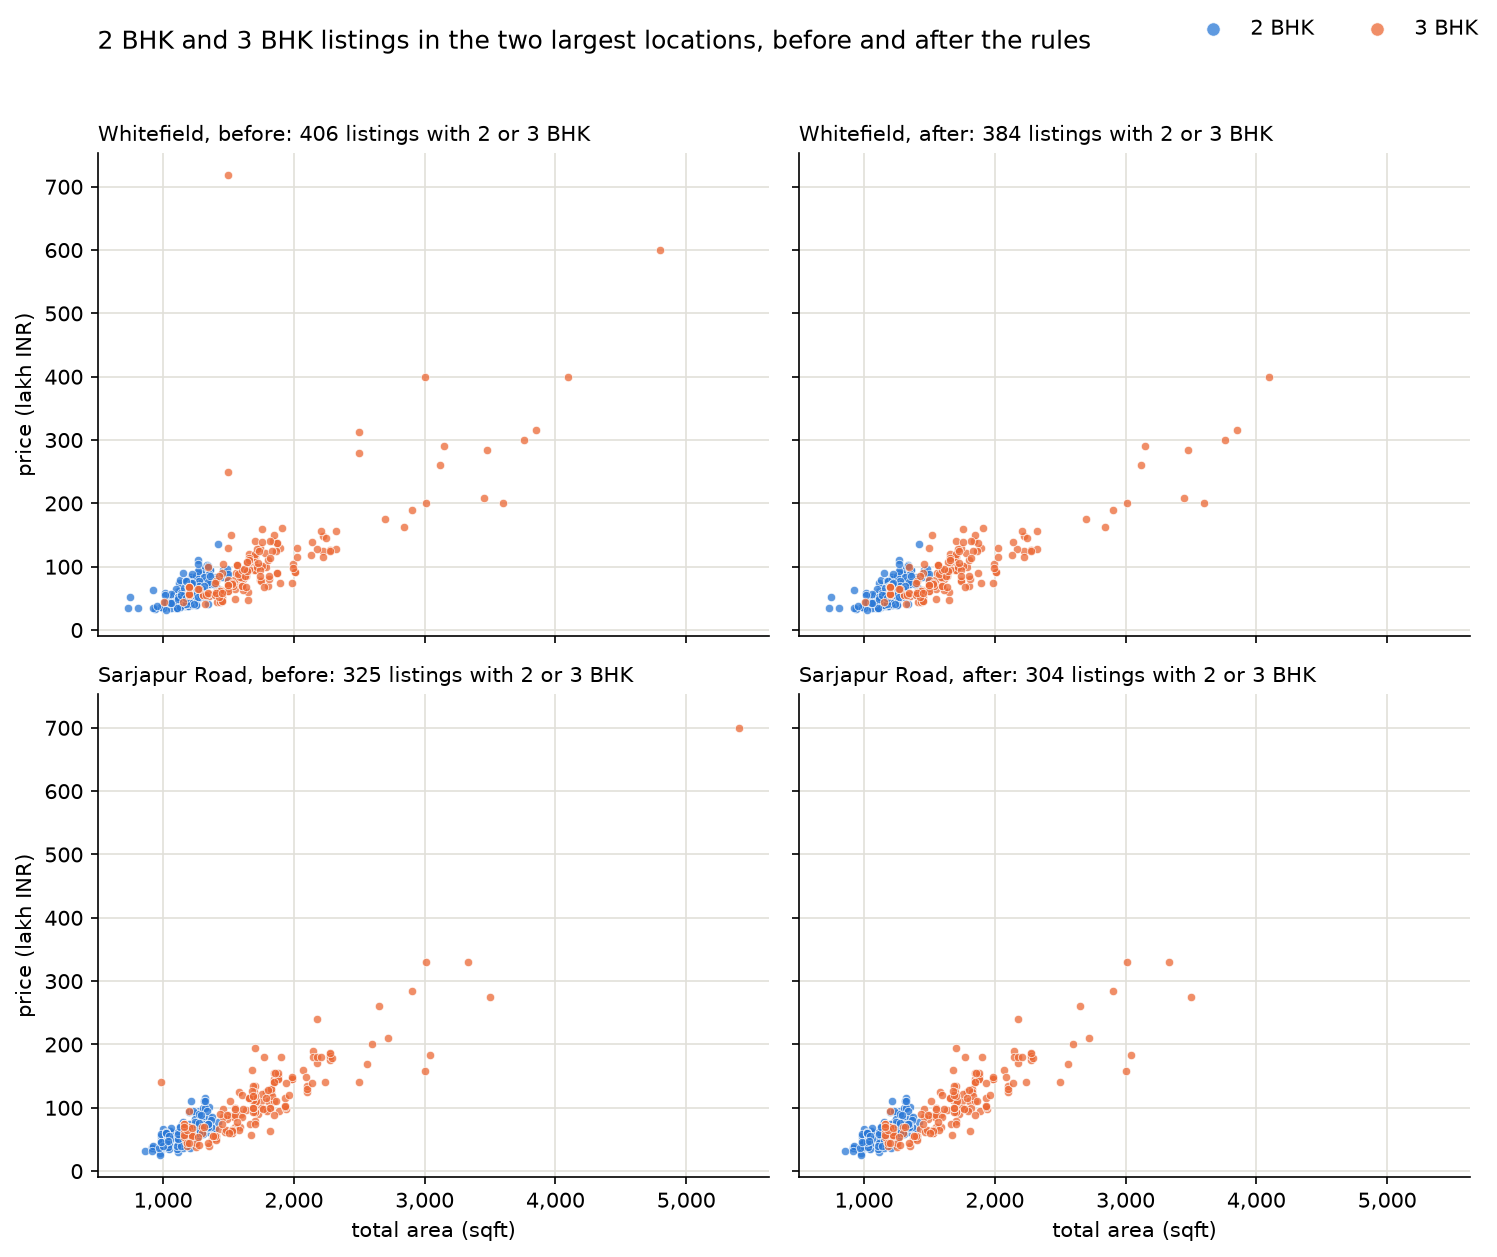

In [54]:
BLUE, ORANGE = "#2a78d6", "#eb6834"                      # categorical slots 1 and 2 of the validated palette
top_two = location_clean.value_counts().index[:2]        # the two largest locations (clean names)

# Which rule removed the 2 and 3 BHK listings that are missing from the "after" pictures, and which are the dearest of them?
rule_of = {label: rule for rule, rows in removed.items() for label in rows.index}      # row label -> the rule that removed it
for place in top_two:
    before = df3[(location_clean == place) & df3["bhk"].isin([2, 3])]
    gone = before.index.difference(df4.index)
    after = before.drop(gone)
    print(f"{place}: {len(before)} listings -> {len(after)}; removed {len(gone)}: {pd.Series([rule_of[i] for i in gone]).value_counts().to_dict()}")
    print(f"  median price_per_sqft {before['price_per_sqft'].median():,.0f} -> {after['price_per_sqft'].median():,.0f}; dearest removed:")
    display(before.loc[gone].nlargest(3, "price")[["total_sqft", "bhk", "price", "price_per_sqft"]].assign(rule=lambda t: t.index.map(rule_of)).round(0))

fig, axes = plt.subplots(2, 2, figsize=(10, 8.4), dpi=150, sharex=True, sharey=True)
for r, place in enumerate(top_two):
    for c, (when, frame) in enumerate([("before", df3), ("after", df4)]):
        ax = axes[r, c]
        in_place = frame[(location_clean.loc[frame.index] == place) & frame["bhk"].isin([2, 3])]
        for bhk, color in [(2, BLUE), (3, ORANGE)]:
            part = in_place[in_place["bhk"] == bhk]
            ax.scatter(part["total_sqft"], part["price"], s=16, color=color, alpha=0.75, edgecolor="white", linewidth=0.4, label=f"{bhk} BHK")
        ax.set_title(f"{place}, {when}: {len(in_place)} listings with 2 or 3 BHK", loc="left", fontsize=10)
        ax.grid(color="#e1e0d9", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.xaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")
        if c == 0:
            ax.set_ylabel("price (lakh INR)")
        if r == 1:
            ax.set_xlabel("total area (sqft)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False, markerscale=1.6)
fig.suptitle("2 BHK and 3 BHK listings in the two largest locations, before and after the rules", x=0.07, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

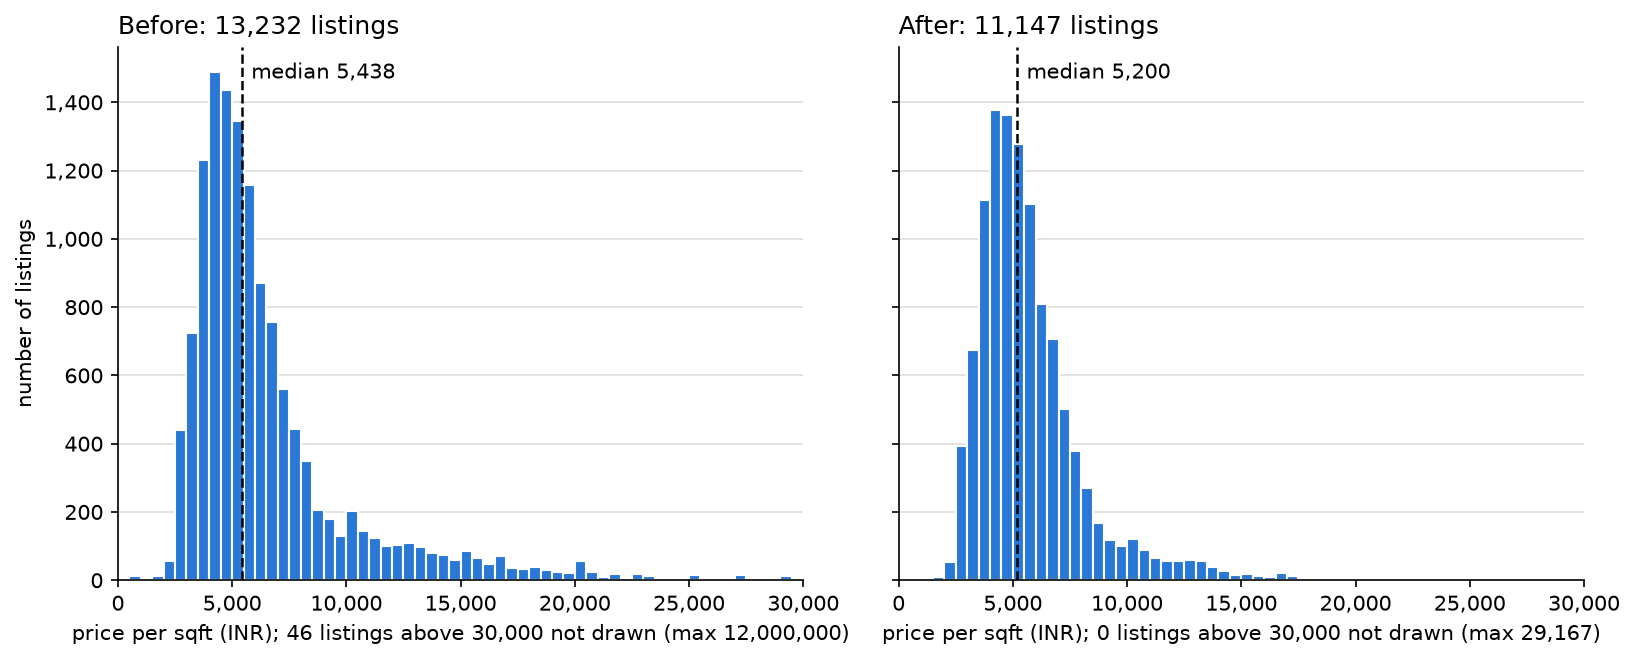

In [55]:
CAP = 30_000                                             # same cap and bins as the Session 2 histogram
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=150, sharex=True, sharey=True)
for ax, (when, frame) in zip(axes, [("Before", df3), ("After", df4)]):
    values = frame["price_per_sqft"]
    n_beyond = int((values > CAP).sum())
    ax.hist(values, bins=60, range=(0, CAP), color="#2a78d6", edgecolor="white")
    ax.axvline(values.median(), color="black", linestyle="--", linewidth=1.2)
    ax.text(values.median() + 400, 0.97, f"median {values.median():,.0f}", va="top", transform=ax.get_xaxis_transform())
    ax.set_title(f"{when}: {len(frame):,} listings", loc="left")
    ax.set_xlabel(f"price per sqft (INR); {n_beyond} listings above {CAP:,} not drawn (max {values.max():,.0f})")
    ax.set_xlim(0, CAP)
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")
    ax.yaxis.set_major_formatter(lambda y, pos: f"{y:,.0f}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#dddddd")
    ax.set_axisbelow(True)
axes[0].set_ylabel("number of listings")
fig.tight_layout(w_pad=2.5)
plt.show()

**What the figures show**

- **Scatter.** Most of the removed 2 and 3 BHK listings are repeats (16 of 22 in Whitefield, 19 of 21 in Sarjapur Road), which sit exactly on top of their first copy, so they are not visible. What disappears from the pictures is the top of each cloud: in Whitefield the 718 lakh listing on 1,496 sqft and the large homes at 600 lakh (4,800 sqft) and 400 lakh (3,000 sqft), in Sarjapur Road the 5,400 sqft listing at 700 lakh, all removed by the location fences. The middle of each cloud does not move (median price per sqft 5,208 before and 5,193 after in Whitefield, 5,523 and 5,570 in Sarjapur Road) and the band from small, cheap 2 BHK homes up to large, dear 3 BHK ones is still there. The price of the largest homes is what is lost, as Rule 3 warned.
- **Histogram.** The bulk is unchanged (median 5,438 before, 5,200 after) and the long right tail is gone: all 46 rows above 30,000 INR per sqft (the highest 12,000,000) are removed, and 218 of the 238 above 20,000 (the highest left is 29,167). The standard deviation falls from 106,601 to 2,507. The left end changes little: 6 of the 17 rows below 1,000 INR per sqft are removed, all by the location fences. They include the two ordinary-size homes that a rule on area would not catch (BTM Layout, 1,798 sqft at 10 lakh; Begur, 2,400 sqft at 12 lakh). The 11 that stay are plot-sized, 9,900 sqft or more.

### The final frame

Checks, then the problems the session started from, before and after.

In [56]:
assert df4.isnull().sum().sum() == 0                                        # no nulls
assert list(df4.columns) == list(df3.columns)                               # same six columns; price_per_sqft stays until Session 5
assert df4.index.is_unique and df4.index.isin(df3.index).all()
assert repeat_flag.loc[df4.index].sum() == 0                                # no repeat left
assert len(df3) - len(df4) == sum(len(rows) for rows in removed.values())   # every missing row is accounted for
print(f"Final shape: {df4.shape}")


def problems(frame):
    return {
        "rows": len(frame),
        "repeated rows (nine raw columns)": int(repeat_flag.loc[frame.index].sum()),
        "smallest total_sqft": frame["total_sqft"].min(),
        "most bedrooms (bhk)": frame["bhk"].max(),
        "rows with 10 or more bedrooms": int((frame["bhk"] >= 10).sum()),
        "dearest listing (lakh)": frame["price"].max(),
        "rows priced 300 lakh or more": int((frame["price"] >= 300).sum()),
        "price_per_sqft: min": frame["price_per_sqft"].min(),
        "price_per_sqft: max": frame["price_per_sqft"].max(),
        "price_per_sqft: standard deviation": frame["price_per_sqft"].std(),
        "price_per_sqft: mean": frame["price_per_sqft"].mean(),
        "price_per_sqft: rows below 1,000": int((frame["price_per_sqft"] < 1_000).sum()),
        "price_per_sqft: rows above 20,000": int((frame["price_per_sqft"] > 20_000).sum()),
        "price_per_sqft: rows above 30,000": int((frame["price_per_sqft"] > 30_000).sum()),
    }


display(pd.DataFrame({"Session 3 frame": problems(df3), "Session 4 frame": problems(df4)}).round(1))
df4[["total_sqft", "bath", "price", "bhk", "price_per_sqft"]].describe().round(1)

Final shape: (11147, 6)


,Session 3 frame,Session 4 frame
rows,13232.0,11147.0
repeated rows (nine raw columns),529.0,0.0
smallest total_sqft,1.0,300.0
most bedrooms (bhk),43.0,16.0
rows with 10 or more bedrooms,26.0,7.0
dearest listing (lakh),3600.0,2200.0
rows priced 300 lakh or more,779.0,406.0
price_per_sqft: min,267.8,267.8
price_per_sqft: max,12000000.0,29166.7
price_per_sqft: standard deviation,106601.3,2507.2


,total_sqft,bath,price,bhk,price_per_sqft
count,11147.0,11147.0,11147.0,11147.0,11147.0
mean,1547.0,2.5,94.9,2.6,5760.1
std,1181.7,1.0,96.5,0.9,2507.2
min,300.0,1.0,9.0,1.0,267.8
25%,1105.0,2.0,48.0,2.0,4190.3
50%,1295.0,2.0,68.0,2.0,5200.0
75%,1665.0,3.0,105.0,3.0,6600.3
max,52272.0,16.0,2200.0,16.0,29166.7


In [57]:
categories = df4["location"].value_counts()
named = categories.drop(OTHER)
print(f"{len(categories)} categories | '{OTHER}' holds {categories[OTHER]:,} rows ({categories[OTHER] / len(df4):.1%}; "
      f"before the rules {(df3['location'] == OTHER).mean():.1%})")
print(f"named locations with {THRESHOLD} or fewer rows left: {(named <= THRESHOLD).sum()} of {len(named)}; the smallest has {named.min()}")

# Session 3 left the nine digit-glued names in place and passed the question of the bad rows among them to this session.
glued_gone = glued_rows.index.difference(df4.index)
print(f"\nof the {len(glued_rows)} digit-glued rows, {len(glued_gone)} were removed: {pd.Series([rule_of[i] for i in glued_gone]).value_counts().to_dict()}")
print("the ones that stay:")
glued_rows.loc[glued_rows.index.isin(df4.index), ["name", "bhk", "bath", "total_sqft", "price"]]

241 categories | 'other' holds 2,302 rows (20.7%; before the rules 21.7%)
named locations with 10 or fewer rows left: 37 of 240; the smallest has 2

of the 9 digit-glued rows, 7 were removed: {'fewer than 300 sqft per bedroom': 6, 'outside the pooled fence (small locations)': 1}
the ones that stay:


,name,bhk,bath,total_sqft,price
4105,Indranagar 100ft road defence colony,5,5.0,5800.0,80.0
9935,1Hoysalanagar,13,13.0,5425.0,275.0


**Result.** The frame went from 13,232 to **11,147 rows** (2,085 removed, 15.8%). It keeps its six columns and has no nulls and no repeats: 529 rows went as repeats, 746 to the domain rules (737 and 9), 575 to the location fences and 235 to the pooled fence. The brief expected roughly 11,000 to 11,500 rows.

**What is still in the frame, and what to carry into Session 5**

- **`price_per_sqft` is still there** and goes first in Session 5, since it is built from the target.
- **The minimum `price_per_sqft` is still 267.8.** 11 rows are below 1,000 INR per sqft, because no fence can flag a row as too cheap where its lower fence is below zero (28 locations and the pooled group). Rule 4 has the table and a log-scale alternative.
- **7 rows still have 10 or more bedrooms** (26 before; the most is 16). Of the 9 digit-glued rows Session 3 passed on, 7 were removed (6 by the area rule, 1 by the pooled fence); the two that stay are "Indranagar 100ft road defence colony" (5 bedrooms) and "1Hoysalanagar" (13 bedrooms and 13 bathrooms on 5,425 sqft).
- **Expensive homes are under-represented**: 406 rows are priced 300 lakh or more, against 779 before.
- **`location` was not touched.** `other` now holds 2,302 rows (20.7%, against 21.7% before), and 37 of the 240 named locations have 10 or fewer rows left (the smallest has 2), because the rules removed rows after the threshold was applied. They keep their names; Session 5, which tests thresholds 5 and 20, can apply the threshold to the cleaned frame.

## Decision log (Sessions 1 to 4)

Each decision with its row impact, as seen while the notebook ran on this data.

| # | Session | Decision | Why | Rows before | Rows after | Rows removed |
|--:|:-------:|----------|-----|------------:|-----------:|-------------:|
| 1 | 1 | Drop `area_type` | Judgment call: changes what `total_sqft` measures; re-test in Session 5 | 13,320 | 13,320 | 0 |
| 2 | 1 | Drop `availability` | Possession label/month, not a property attribute | 13,320 | 13,320 | 0 |
| 3 | 1 | Drop `society` | Large share missing and very high-cardinality | 13,320 | 13,320 | 0 |
| 4 | 1 | Drop `balcony` | Minor amenity count; avoids imputing | 13,320 | 13,320 | 0 |
| 5 | 1 | Drop rows with a null in `location`, `size` or `bath` | `location` has no sensible fill value; `bath` is tied to bedroom count (`size`), so imputing would invent data | 13,320 | 13,246 | 74 |
| 6 | 2 | `bhk` = leading integer of `size` | Every row matched the pattern (asserted) | 13,246 | 13,246 | 0 |
| 7 | 2 | Keep the 13 "RK" rows, with `bhk = 1` | All are 1 RK with one bathroom and a small area; dropping them removes a listing type, and `bhk = 0` would be a value seen 13 times | 13,246 | 13,246 | 0 |
| 8 | 2 | `total_sqft` ranges become their midpoint (144 rows) | The usual convention; the widest range (3067 - 8156) is 5,089 sqft wide | 13,246 | 13,246 | 0 |
| 9 | 2 | Convert 32 unit-string rows to sqft (17 Sq. Meter × 10.7639, 15 Sq. Yards × 9) | Exact, universal factors | 13,246 | 13,246 | 0 |
| 10 | 2 | Drop the 14 other unit-string rows (8 Acres, 2 Cents, 2 Guntha, 1 Perch, 1 Grounds) | Land-parcel units: farmland scale or region-defined | 13,246 | 13,232 | 14 |
| 11 | 2 | Add `price_per_sqft` = `price` × 100,000 / `total_sqft` (INR per sqft) | For spotting outliers in Session 4 only; built from the target, so never a model input | 13,232 | 13,232 | 0 |
| 12 | 2 | Drop `size` | Replaced by `bhk`, which is complete | 13,232 | 13,232 | 0 |
| 13 | 3 | Strip and collapse whitespace in `location` | Fixes spellings such as "Sarjapur  Road" (two spaces): 1,299 → 1,288 distinct names | 13,232 | 13,232 | 0 |
| 14 | 3 | Merge case variants: casefolded key, clean name = the key's most frequent spelling | "JP Nagar" and "jp nagar" are one place, and the website can later show readable names: 1,288 → 1,276 | 13,232 | 13,232 | 0 |
| 15 | 3 | Remove trailing commas and periods (59 rows) | "Kudlu Village," is "Kudlu Village": 1,276 → 1,266; the `)` that closes a bracket in one name is kept | 13,232 | 13,232 | 0 |
| 16 | 3 | Replace locations with 10 or fewer listings by `other` (threshold 10) | Too few examples to learn a location effect: 1,026 locations and 2,868 rows (21.7%) go to `other`, leaving 240 named locations (241 categories) | 13,232 | 13,232 | 0 |
| 17 | 3 | Leave the 9 digit-glued names as they are | Not hand-edited; each has one listing, so all of them fall into `other` | 13,232 | 13,232 | 0 |
| 18 | 4 | Remove the 529 repeated rows (`df_raw.duplicated()` on all nine raw columns, keep the first, matched by index) | A repeat would sit on both sides of the split and count twice in every quartile; the five kept columns would flag 888 and include different flats | 13,232 | 12,703 | 529 |
| 19 | 4 | Remove rows with fewer than 300 sqft per bedroom | Area and bedroom count cannot both be right; 250 would keep 132 of the rows, 350 would remove 349 more | 12,703 | 11,966 | 737 |
| 20 | 4 | Remove rows with more than `bhk + 2` bathrooms | Only the 9 rows the area rule had not taken; they are mostly large, expensive houses | 11,966 | 11,957 | 9 |
| 21 | 4 | Remove rows outside the IQR fences of their own clean location (230 locations with 10 or more rows) | Quartiles resist the outliers: mean ± 1 SD would flag 15.1% of the rows against 4.8%. 519 rows above the upper fence, 56 below | 11,957 | 11,382 | 575 |
| 22 | 4 | Remove rows outside one pooled IQR fence (−1,667 to 14,333) for the 2,589 rows of places with fewer than 10 rows | All 235 are above the upper fence and come mostly from small, expensive places; the fence cannot flag a row as too cheap (a log-scale alternative is reported, not applied) | 11,382 | 11,147 | 235 |
| 23 | 4 | Report only: 3 BHK rows below the 2 BHK average of their location | 1,508 of 3,919 comparable rows (38.5%), too common to be a sign of error | 11,147 | 11,147 | 0 |
| 24 | 4 | Keep `price_per_sqft` and the grouped `location` as they are | `price_per_sqft` goes first in Session 5; the Session 3 threshold is not applied again after the removals | 11,147 | 11,147 | 0 |

**Result:** 13,320 rows × 9 columns → 11,147 rows × 6 columns (`location`, `total_sqft`, `bath`, `price`, `bhk`, `price_per_sqft`), zero nulls. 2,173 rows removed in total, 16.3% of the raw data: 88 in Sessions 1 and 2, and 2,085 in Session 4 (15.8% of the 13,232 rows). `price` is still in lakhs of INR.

**Left in on purpose, or beyond the rules:** `price_per_sqft` (until Session 5), the 11 rows below 1,000 INR per sqft and the 7 rows with 10 or more bedrooms.

## Open items carried forward

1. **Session 5, first step: drop `price_per_sqft`.** It is built from the target and must never be a model input.
2. **A decision on the pooled fence.** Its lower fence is below zero (as it is in 28 named locations), so the 11 rows under 1,000 INR per sqft stay and the minimum is still 267.8, and its upper fence cuts small, expensive places. A fence on log(`price_per_sqft`) would flag 80 rows instead of 235 and would catch the low ones. It is not applied (Rule 4).
3. **The rules and the location grouping use all rows**, including rows that will later be test data. A stricter version would compute them on the training rows only (see the README).
4. **Session 5 tests**: thresholds 5 and 20 on the cleaned frame (37 named locations now have 10 or fewer rows); scores with and without the repeats; errors reported separately for named locations and `other`, and by price band (47.9% of the listings priced 300 lakh or more were removed). Session 6 decides how the website treats `other`.